# PN post-inference analysis — ratio/brightness contours

This notebook analyzes saved PN inference results without rerunning the neural network. It provides:

1. localization errors for recovered catalogue PNe;
2. localization summary statistics and diagnostic plots;
3. real-vs-synthetic PN domain diagnostics using both Hα/[O III] and Hβ/[O III] versus $m_{5007}$;
4. synthetic-PN density contours with real PN network scores overlaid;
5. binned catalogue-PN recovery fraction in spectral-ratio–brightness space;
6. optional 3-D network-score views;
7. reproducible score-stratified samples and 32×32 cutout grids.

For recovered PNe, cutouts show `+` at the network position and `x` at the catalogue position. Missed PNe are centered on the catalogue position; unmatched candidates are centered on the network position.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.io import fits
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales
from matplotlib.colors import AsinhNorm
from matplotlib.ticker import ScalarFormatter
from scipy.ndimage import gaussian_filter

# Paths
RESULTS_CSV = Path("/Users/golta/Neb_det/output/PN_detection/inference/pn_diagnostics_v4.6/diagnostic_source_measurements_v4.2.csv")
ORIGINAL_FITS_PATH = Path("/Users/golta/Neb_det/data/ADP.2025-07-06T07_52_11.876.fits")
SYNTHETIC_DATASET = Path("/Users/golta/Neb_det/output/PN_detection/synthesizer/all_PN_20000_grouped_norm_v6.2_diffuse_HII.npz")
OUTPUT_DIR = Path("/Users/golta/Neb_det/output/PN_detection/inference/pn_post_inference_v1_3")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Analysis settings
RANDOM_SEED = 20260916
CUTOUT_SIZE = 32
N_PER_SCORE_BIN = 10
DETECTION_THRESHOLD = 0.45
DISPLAY_PERCENTILES = (1.0, 99.5)

# Population labels
POP_MATCHED = "Recovered catalogue PN"
POP_MISSED = "Missed catalogue PN"
POP_UNMATCHED = "Unmatched candidate"
REAL_PN_POPULATIONS = (POP_MATCHED, POP_MISSED)

DETECTED_SCORE_BINS = (
    (0.45, 0.60, "0.45–0.60"),
    (0.60, 0.80, "0.60–0.80"),
    (0.80, np.inf, ">=0.80"),
)
MISSED_SCORE_BINS = (
    (0.00, 0.15, "<0.15"),
    (0.15, 0.30, "0.15–0.30"),
    (0.30, 0.45, "0.30–0.45"),
)

print("Results table :", RESULTS_CSV)
print("MUSE FITS     :", ORIGINAL_FITS_PATH)
print("Synthetic data:", SYNTHETIC_DATASET)
print("Output folder :", OUTPUT_DIR)


Results table : /Users/golta/Neb_det/output/PN_detection/inference/pn_diagnostics_v4.6/diagnostic_source_measurements_v4.2.csv
MUSE FITS     : /Users/golta/Neb_det/data/ADP.2025-07-06T07_52_11.876.fits
Synthetic data: /Users/golta/Neb_det/output/PN_detection/synthesizer/all_PN_20000_grouped_norm_v6.2_diffuse_HII.npz
Output folder : /Users/golta/Neb_det/output/PN_detection/inference/pn_post_inference_v1_3


## 1. Shared helpers

Small helpers isolate validation, I/O, coordinate selection, sampling, formatting, and display normalization. This keeps later analysis cells declarative.


In [2]:
REQUIRED_COLUMNS = {
    "population", "object_id", "center_x", "center_y",
    "catalog_x", "catalog_y", "network_score", "edge_object",
}


def require_columns(table, columns, context="table"):
    missing = sorted(set(columns) - set(table.columns))
    if missing:
        raise ValueError(f"{context} is missing required columns: {', '.join(missing)}")


def coerce_bool_column(series):
    """Normalize common CSV boolean representations while preserving missing values."""
    if series.dtype != object:
        return series
    return series.astype(str).str.strip().str.lower().map({"true": True, "false": False})


def load_flux_maps(path):
    extensions = {
        "Hβ": "HB4861_FLUX",
        "[O III]": "OIII5006_FLUX",
        "Hα": "HA6562_FLUX",
        "[N II]": "NII6583_FLUX",
    }
    images = {}
    with fits.open(path) as hdul:
        for label, extension in extensions.items():
            image = np.asarray(hdul[extension].data, dtype=np.float32).squeeze()
            if image.ndim != 2:
                raise ValueError(f"Expected a 2-D {label} map, got {image.shape}")
            images[label] = image
        oiii_header = hdul[extensions["[O III]"]].header.copy()

    shapes = {image.shape for image in images.values()}
    if len(shapes) != 1:
        raise ValueError(f"Flux maps have inconsistent shapes: {sorted(shapes)}")

    images["Sum"] = sum(images.values())
    return images, oiii_header


def extract_cutout(image, x, y, size=CUTOUT_SIZE):
    half = size // 2
    x0 = int(np.round(x)) - half
    y0 = int(np.round(y)) - half
    x1, y1 = x0 + size, y0 + size
    height, width = image.shape

    if x0 < 0 or y0 < 0 or x1 > width or y1 > height:
        return None, None
    return image[y0:y1, x0:x1], (x0, y0)


def make_asinh_norm(cutout, percentiles=DISPLAY_PERCENTILES):
    finite = cutout[np.isfinite(cutout)]
    if finite.size == 0:
        return None

    vmin, vmax = np.percentile(finite, percentiles)
    if not np.isfinite(vmin) or not np.isfinite(vmax) or vmax <= vmin:
        vmin, vmax = np.nanmin(finite), np.nanmax(finite)
    if vmax <= vmin:
        vmax = vmin + 1.0

    linear_width = max(0.05 * (vmax - vmin), np.finfo(float).eps)
    return AsinhNorm(linear_width=linear_width, vmin=vmin, vmax=vmax)


def finite_value(value, fmt=".2f"):
    try:
        value = float(value)
    except (TypeError, ValueError):
        return "—"
    return format(value, fmt) if np.isfinite(value) else "—"


def display_center(source, population):
    """Use the catalogue center for missed PNe; network center otherwise."""
    if population == POP_MISSED:
        return float(source["catalog_x"]), float(source["catalog_y"])
    return float(source["center_x"]), float(source["center_y"])


def sample_score_bins(table, population, score_bins, n_per_bin=N_PER_SCORE_BIN, seed=RANDOM_SEED):
    required_positions = ("catalog_x", "catalog_y") if population == POP_MISSED else ("center_x", "center_y")
    valid = (
        table["population"].eq(population)
        & ~table["edge_object"].fillna(True)
        & np.isfinite(table["network_score"])
        & np.isfinite(table[required_positions[0]])
        & np.isfinite(table[required_positions[1]])
    )
    population_df = table.loc[valid].copy()
    samples = []

    for bin_index, (low, high, label) in enumerate(score_bins):
        in_bin = population_df[population_df["network_score"].ge(low)]
        if np.isfinite(high):
            in_bin = in_bin[in_bin["network_score"].lt(high)]

        n_take = min(n_per_bin, len(in_bin))
        if n_take == 0:
            print(f"WARNING: {population}, score bin {label}: no objects.")
            continue
        if n_take < n_per_bin:
            print(f"WARNING: {population}, score bin {label}: only {len(in_bin)} objects available.")

        sampled = in_bin.sample(n=n_take, replace=False, random_state=seed + bin_index).copy()
        sampled["score_bin"] = label
        samples.append(sampled)

    return pd.concat(samples, ignore_index=True) if samples else pd.DataFrame()


## 2. Load and validate inference results + MUSE flux maps


In [3]:
diagnostic_table = pd.read_csv(RESULTS_CSV)
require_columns(diagnostic_table, REQUIRED_COLUMNS, "Saved diagnostic table")
diagnostic_table["edge_object"] = coerce_bool_column(diagnostic_table["edge_object"])

channel_images, oiii_header = load_flux_maps(ORIGINAL_FITS_PATH)
oiii_flux = channel_images["[O III]"]

wcs = WCS(oiii_header).celestial
pixel_scales_deg = proj_plane_pixel_scales(wcs)
PIXEL_SCALE_ARCSEC = float(np.mean(np.abs(pixel_scales_deg)) * 3600.0)

print("Objects in saved table:")
display(diagnostic_table.groupby("population").size().rename("N").reset_index())
print("Flux-map shape:", oiii_flux.shape)
print(f"Pixel scale   : {PIXEL_SCALE_ARCSEC:.5f} arcsec/pixel")


Objects in saved table:


,population,N
0,Missed catalogue PN,71
1,Recovered catalogue PN,500
2,Unmatched candidate,1101


Flux-map shape: (1733, 6080)
Pixel scale   : 0.20000 arcsec/pixel


## 3. Localization errors for recovered catalogue PNe

$\Delta x=x_{network}-x_{catalogue}$, $\Delta y=y_{network}-y_{catalogue}$, and $\Delta r=\sqrt{\Delta x^2+\Delta y^2}$.


In [4]:
def add_localization_errors(table, pixel_scale_arcsec):
    matched = table.loc[table["population"].eq(POP_MATCHED)].copy()
    coordinate_columns = ["center_x", "center_y", "catalog_x", "catalog_y"]
    matched = matched.loc[np.isfinite(matched[coordinate_columns]).all(axis=1)].copy()

    matched["localization_dx_pix"] = matched["center_x"] - matched["catalog_x"]
    matched["localization_dy_pix"] = matched["center_y"] - matched["catalog_y"]
    matched["localization_error_pix"] = np.hypot(
        matched["localization_dx_pix"], matched["localization_dy_pix"]
    )

    for component in ("dx", "dy", "error"):
        matched[f"localization_{component}_arcsec"] = (
            matched[f"localization_{component}_pix"] * pixel_scale_arcsec
        )
    return matched


def summarize_localization(matched, pixel_scale_arcsec):
    r = matched["localization_error_pix"].dropna().to_numpy(float)
    dx = matched["localization_dx_pix"].dropna().to_numpy(float)
    dy = matched["localization_dy_pix"].dropna().to_numpy(float)

    def stat(values, fn):
        return fn(values) if values.size else np.nan

    summary = {
        "N_matched": r.size,
        "mean_dx_pix": stat(dx, np.mean),
        "median_dx_pix": stat(dx, np.median),
        "mean_dy_pix": stat(dy, np.mean),
        "median_dy_pix": stat(dy, np.median),
        "mean_radial_error_pix": stat(r, np.mean),
        "median_radial_error_pix": stat(r, np.median),
        "p68_radial_error_pix": stat(r, lambda x: np.percentile(x, 68)),
        "p90_radial_error_pix": stat(r, lambda x: np.percentile(x, 90)),
        "p95_radial_error_pix": stat(r, lambda x: np.percentile(x, 95)),
        "max_radial_error_pix": stat(r, np.max),
    }
    for key, value in list(summary.items()):
        if key.endswith("radial_error_pix"):
            summary[key.replace("_pix", "_arcsec")] = value * pixel_scale_arcsec
    return pd.DataFrame([summary])


matched = add_localization_errors(diagnostic_table, PIXEL_SCALE_ARCSEC)

if "match_distance_pix" in matched:
    difference = matched["localization_error_pix"] - matched["match_distance_pix"]
    difference = difference[np.isfinite(difference)]
    if not difference.empty:
        print(f"Max |recomputed error - saved match distance|: {difference.abs().max():.3e} pix")

localization_columns = [
    "object_id", "catalog_id", "catalog_x", "catalog_y", "center_x", "center_y",
    "network_score", "localization_dx_pix", "localization_dy_pix",
    "localization_error_pix", "localization_dx_arcsec", "localization_dy_arcsec",
    "localization_error_arcsec",
]
localization_table = matched[[c for c in localization_columns if c in matched]].copy()
localization_summary = summarize_localization(matched, PIXEL_SCALE_ARCSEC)

localization_table.to_csv(OUTPUT_DIR / "matched_localization_errors.csv", index=False)
localization_summary.to_csv(OUTPUT_DIR / "localization_summary.csv", index=False)

display(localization_summary)
display(localization_table.head())


Max |recomputed error - saved match distance|: 2.405e-04 pix


,N_matched,mean_dx_pix,median_dx_pix,mean_dy_pix,median_dy_pix,mean_radial_error_pix,median_radial_error_pix,p68_radial_error_pix,p90_radial_error_pix,p95_radial_error_pix,max_radial_error_pix,mean_radial_error_arcsec,median_radial_error_arcsec,p68_radial_error_arcsec,p90_radial_error_arcsec,p95_radial_error_arcsec,max_radial_error_arcsec
0,500,0.064776,0.02852,0.02842,3.727223e-10,0.441679,0.40833,0.512049,0.745748,1.000001,1.414214,0.088336,0.081666,0.10241,0.14915,0.2,0.282843


,object_id,catalog_id,catalog_x,catalog_y,center_x,center_y,network_score,localization_dx_pix,localization_dy_pix,localization_error_pix,localization_dx_arcsec,localization_dy_arcsec,localization_error_arcsec
0,PN_1,1.0,1048.627172,768.130699,1049.0,768.0,0.738082,0.372828,-0.130699,0.395073,0.074566,-0.026140,0.079015
1,PN_2,2.0,938.519031,719.198444,939.0,719.0,0.612574,0.480969,-0.198444,0.520299,0.096194,-0.039689,0.104060
2,PN_3,3.0,300.579898,804.410077,301.0,804.0,0.712307,0.420102,-0.410077,0.587068,0.084020,-0.082015,0.117414
3,PN_4,4.0,944.981903,772.147353,945.0,772.0,0.751803,0.018097,-0.147353,0.148460,0.003619,-0.029471,0.029692
4,PN_5,5.0,988.645826,763.612216,988.0,763.0,0.577793,-0.645826,-0.612216,0.889888,-0.129165,-0.122443,0.177978


## 4. Localization diagnostic plots


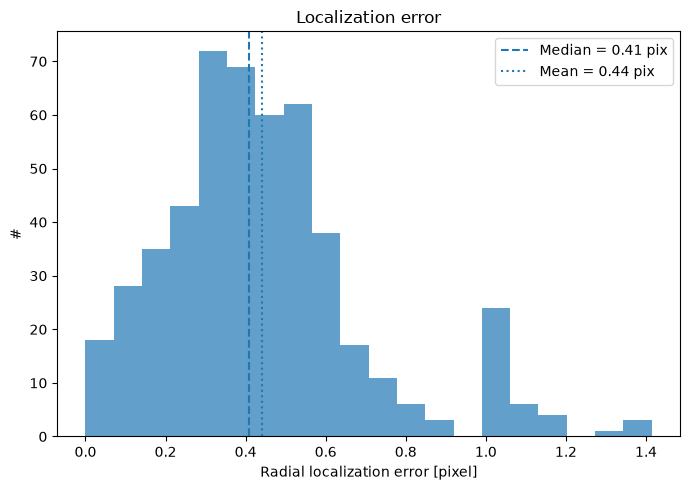

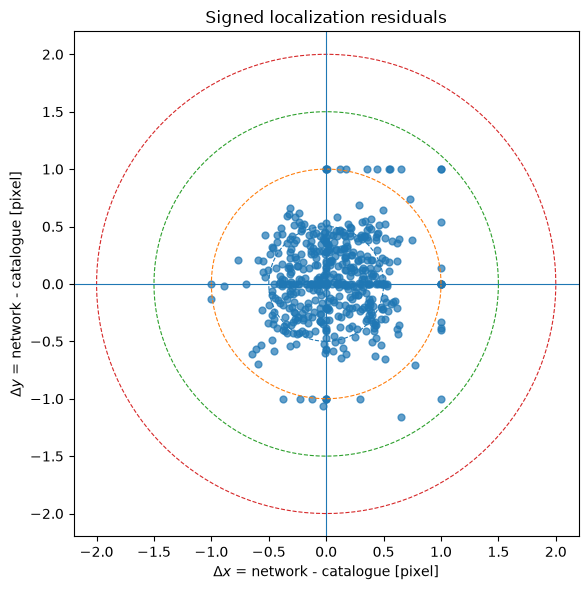

Mean signed offset: dx=0.065 pix, dy=0.028 pix


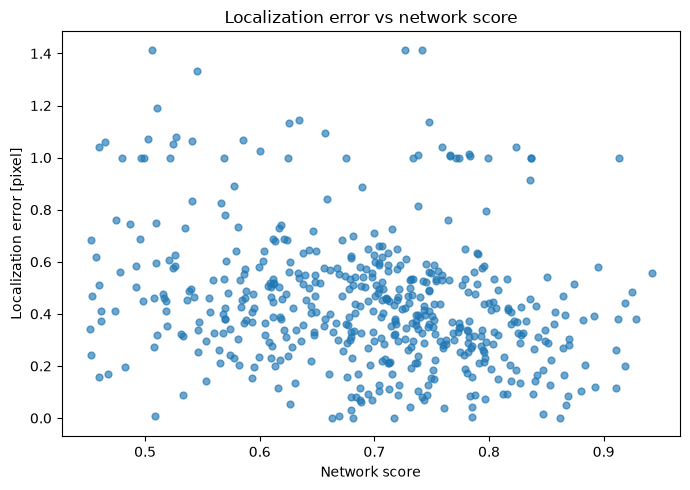

In [5]:
radial_error = matched["localization_error_pix"].dropna().to_numpy(float)

fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(radial_error, bins=20, alpha=0.7)
ax.axvline(np.median(radial_error), linestyle="--", label=f"Median = {np.median(radial_error):.2f} pix")
ax.axvline(np.mean(radial_error), linestyle=":", label=f"Mean = {np.mean(radial_error):.2f} pix")
ax.set(xlabel="Radial localization error [pixel]", ylabel="#", title="Localization error")
ax.legend()
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 6))
dx = matched["localization_dx_pix"].to_numpy(float)
dy = matched["localization_dy_pix"].to_numpy(float)
ax.scatter(dx, dy, s=24, alpha=0.7)
theta = np.linspace(0, 2 * np.pi, 300)
for radius in (0.5, 1.0, 1.5, 2.0):
    ax.plot(radius * np.cos(theta), radius * np.sin(theta), linestyle="--", linewidth=0.8)
ax.axhline(0, linewidth=0.8)
ax.axvline(0, linewidth=0.8)
ax.set_aspect("equal", adjustable="box")
ax.set(xlabel=r"$\Delta x$ = network - catalogue [pixel]", ylabel=r"$\Delta y$ = network - catalogue [pixel]", title="Signed localization residuals")
fig.tight_layout()
plt.show()
print(f"Mean signed offset: dx={np.nanmean(dx):.3f} pix, dy={np.nanmean(dy):.3f} pix")

score_vs_error = matched.loc[np.isfinite(matched["network_score"]) & np.isfinite(matched["localization_error_pix"])]
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(score_vs_error["network_score"], score_vs_error["localization_error_pix"], s=24, alpha=0.65)
ax.set(xlabel="Network score", ylabel="Localization error [pixel]", title="Localization error vs network score")
fig.tight_layout()
plt.show()


## 5. PN recovery in spectral-ratio–brightness space

This section compares real catalogue PNe with the synthetic PN training domain using **both** Hα/[O III] and Hβ/[O III].

- Synthetic contours show the density of injected PN sources in log-ratio versus $m_{5007}$.
- Real catalogue PNe are overlaid and colored by network score; marker shape separates recovered and missed PNe.
- A second figure bins the real catalogue PNe and shows the empirical recovery fraction in the same two planes.
- The 3-D figure is optional and uses network score as the vertical axis.

Only finite positive line ratios are used. The real ratios therefore inherit the S/N cuts used when the diagnostic table was created.


In [6]:
DOMAIN_COLUMNS = {
    "population", "object_id", "network_score",
    "ha_over_oiii", "hb_over_oiii", "catalog_m5007", "edge_object"
}
require_columns(diagnostic_table, DOMAIN_COLUMNS, "Domain diagnostic")

real_mask = (
    diagnostic_table["population"].isin(REAL_PN_POPULATIONS)
    & ~diagnostic_table["edge_object"].fillna(True)
    & np.isfinite(diagnostic_table["network_score"])
    & np.isfinite(diagnostic_table["catalog_m5007"])
)
real_pn_domain = diagnostic_table.loc[real_mask].copy()

RATIO_SPECS = {
    "ha_over_oiii": {"label": r"H$\alpha$/[O III]", "short": "ha", "plain": "Hα/[O III]"},
    "hb_over_oiii": {"label": r"H$\beta$/[O III]", "short": "hb", "plain": "Hβ/[O III]"},
}


def valid_ratio_rows(table, ratio_col):
    return table.loc[
        np.isfinite(table[ratio_col])
        & table[ratio_col].gt(0)
        & np.isfinite(table["catalog_m5007"])
        & np.isfinite(table["network_score"])
    ].copy()


def load_synthetic_pn_domain(path):
    with np.load(path, allow_pickle=True) as synth_npz:
        if "metadata_json" not in synth_npz:
            raise KeyError(f"{path} has no metadata_json field.")
        metadata = json.loads(synth_npz["metadata_json"].item())

    rows = []
    for sample in metadata:
        for source in sample.get("sources", []):
            if str(source.get("class", "")).upper() != "PN":
                continue
            fluxes = source.get("line_fluxes", {})
            hb = float(fluxes.get("Hbeta", np.nan))
            ha = float(fluxes.get("Halpha", np.nan))
            oiii = float(fluxes.get("OIII5007", np.nan))
            m5007 = float(source.get("m5007", np.nan))
            if not (np.isfinite(oiii) and oiii > 0 and np.isfinite(m5007)):
                continue
            rows.append({
                "hb_over_oiii": hb / oiii if np.isfinite(hb) and hb > 0 else np.nan,
                "ha_over_oiii": ha / oiii if np.isfinite(ha) and ha > 0 else np.nan,
                "m5007": m5007,
            })

    domain = pd.DataFrame(rows)
    if domain.empty:
        raise ValueError("No PN source metadata could be extracted from the synthetic dataset.")
    return domain


synthetic_pn_domain = load_synthetic_pn_domain(SYNTHETIC_DATASET)

coverage_rows = []
for ratio_col, spec in RATIO_SPECS.items():
    real = valid_ratio_rows(real_pn_domain, ratio_col)
    synthetic = synthetic_pn_domain.loc[
        np.isfinite(synthetic_pn_domain[ratio_col])
        & synthetic_pn_domain[ratio_col].gt(0)
        & np.isfinite(synthetic_pn_domain["m5007"])
    ].copy()

    ratio_lo, ratio_hi = np.percentile(synthetic[ratio_col], [1, 99])
    mag_lo, mag_hi = np.percentile(synthetic["m5007"], [1, 99])
    inside = real[ratio_col].between(ratio_lo, ratio_hi) & real["catalog_m5007"].between(mag_lo, mag_hi)
    real = real.assign(inside_synthetic_1_99_box=inside)

    for population in REAL_PN_POPULATIONS:
        group = real.loc[real["population"].eq(population)]
        coverage_rows.append({
            "ratio": spec["label"],
            "population": population,
            "N": len(group),
            "median_network_score": group["network_score"].median(),
            "median_ratio": group[ratio_col].median(),
            "median_m5007": group["catalog_m5007"].median(),
            "fraction_inside_synthetic_1_99_box": group["inside_synthetic_1_99_box"].mean(),
            "synthetic_ratio_1pct": ratio_lo,
            "synthetic_ratio_99pct": ratio_hi,
            "synthetic_m5007_1pct": mag_lo,
            "synthetic_m5007_99pct": mag_hi,
        })

domain_coverage = pd.DataFrame(coverage_rows)
domain_coverage.to_csv(OUTPUT_DIR / "real_vs_synthetic_domain_coverage_two_ratios.csv", index=False)

print(f"Real catalogue PNe before ratio-specific filtering: {len(real_pn_domain)}")
print(f"Synthetic PN sources: {len(synthetic_pn_domain)}")
display(domain_coverage)


Real catalogue PNe before ratio-specific filtering: 571
Synthetic PN sources: 15899


,ratio,population,N,median_network_score,median_ratio,median_m5007,fraction_inside_synthetic_1_99_box,synthetic_ratio_1pct,synthetic_ratio_99pct,synthetic_m5007_1pct,synthetic_m5007_99pct
0,H$\alpha$/[O III],Recovered catalogue PN,458,0.703479,0.333150,25.2575,0.864629,0.206072,1.760848,22.096411,27.86643
1,H$\alpha$/[O III],Missed catalogue PN,68,0.368159,0.912581,25.9765,0.691176,0.206072,1.760848,22.096411,27.86643
2,H$\beta$/[O III],Recovered catalogue PN,402,0.699727,0.101093,25.1670,0.863184,0.055767,0.364736,22.096411,27.86643
3,H$\beta$/[O III],Missed catalogue PN,61,0.363120,0.203587,25.9730,0.590164,0.055767,0.364736,22.096411,27.86643


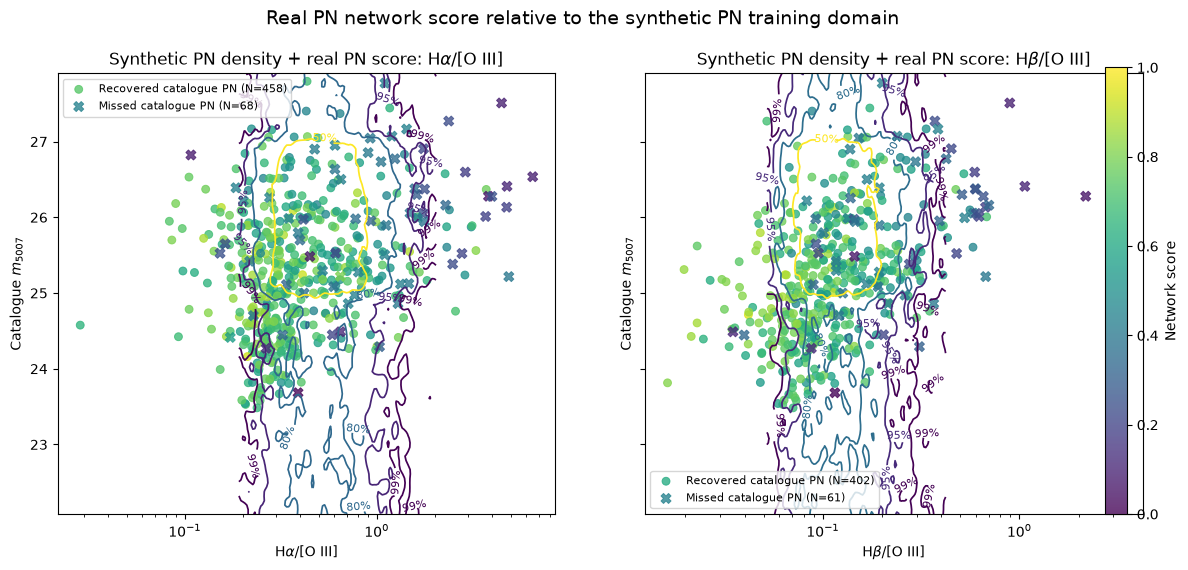

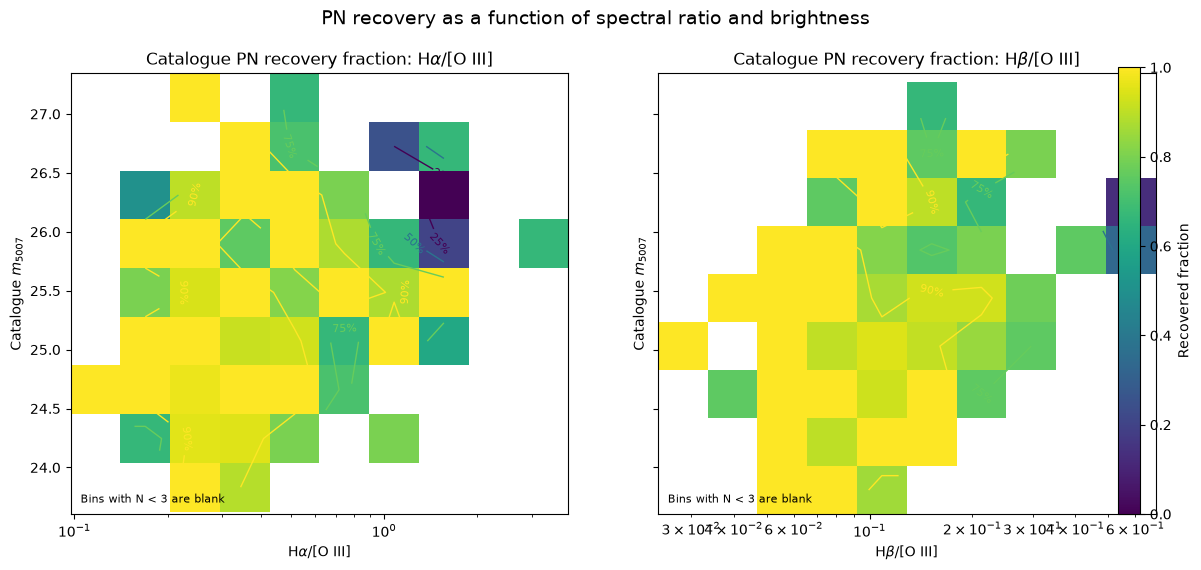

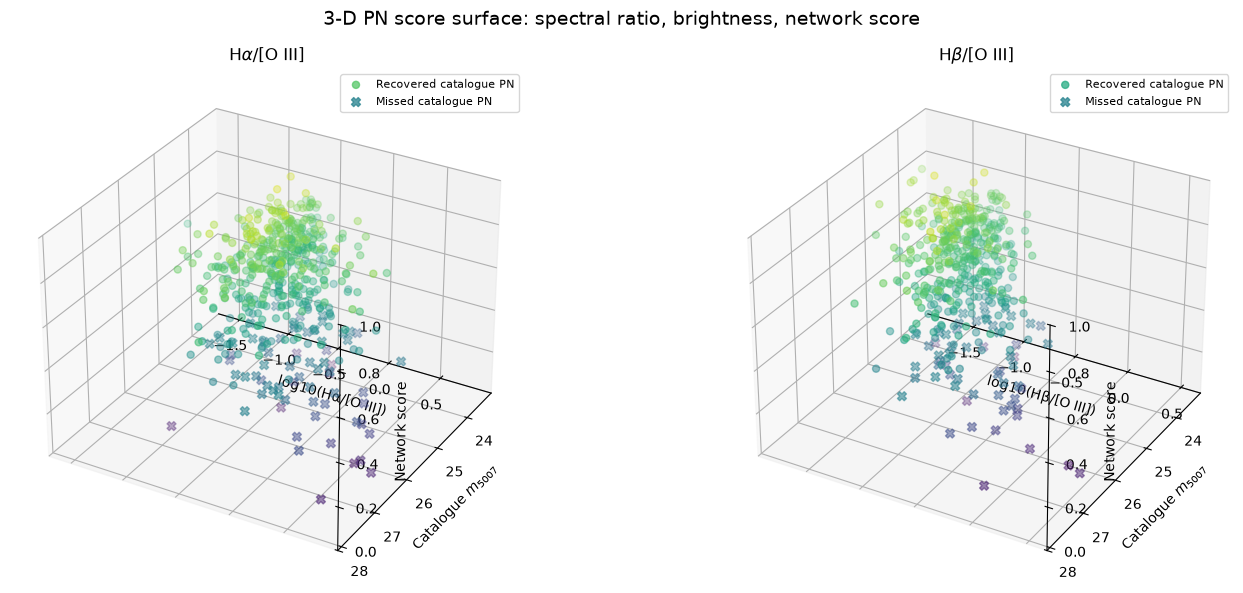

In [7]:
def synthetic_density_grid(synthetic, ratio_col, bins=100, smooth_sigma=1.3, enclosed=(0.50, 0.80, 0.95, 0.99)):
    ratio = synthetic[ratio_col].to_numpy(float)
    mag = synthetic["m5007"].to_numpy(float)
    good = np.isfinite(ratio) & (ratio > 0) & np.isfinite(mag)
    log_ratio = np.log10(ratio[good])
    mag = mag[good]

    x_lo, x_hi = np.percentile(log_ratio, [0.5, 99.5])
    y_lo, y_hi = np.percentile(mag, [0.5, 99.5])
    hist, x_edges, y_edges = np.histogram2d(
        log_ratio, mag, bins=bins, range=[[x_lo, x_hi], [y_lo, y_hi]]
    )
    density = gaussian_filter(hist, smooth_sigma)
    x_centers = 0.5 * (x_edges[:-1] + x_edges[1:])
    y_centers = 0.5 * (y_edges[:-1] + y_edges[1:])

    flat = density.ravel()
    order = np.argsort(flat)[::-1]
    cumulative = np.cumsum(flat[order])
    cumulative /= cumulative[-1]

    level_pairs = []
    for fraction in enclosed:
        index = min(np.searchsorted(cumulative, fraction), len(order) - 1)
        level_pairs.append((float(flat[order[index]]), fraction))

    # contour() requires strictly increasing unique levels.
    level_to_fraction = {}
    for level, fraction in level_pairs:
        if level > 0:
            level_to_fraction[level] = fraction
    levels = np.array(sorted(level_to_fraction), dtype=float)
    labels = {level: f"{int(round(100 * level_to_fraction[level]))}%" for level in levels}

    return 10**x_centers, y_centers, density.T, levels, labels


def plot_domain_contour(ax, ratio_col, ratio_label):
    synthetic = synthetic_pn_domain.loc[
        np.isfinite(synthetic_pn_domain[ratio_col])
        & synthetic_pn_domain[ratio_col].gt(0)
        & np.isfinite(synthetic_pn_domain["m5007"])
    ]
    x, y, density, levels, labels = synthetic_density_grid(synthetic, ratio_col)
    if levels.size:
        contours = ax.contour(x, y, density, levels=levels, linewidths=1.25)
        ax.clabel(contours, fmt=labels, fontsize=8, inline=True)

    markers = {POP_MATCHED: "o", POP_MISSED: "X"}
    sizes = {POP_MATCHED: 32, POP_MISSED: 52}
    artist = None
    for population in REAL_PN_POPULATIONS:
        group = valid_ratio_rows(real_pn_domain.loc[real_pn_domain["population"].eq(population)], ratio_col)
        artist = ax.scatter(
            group[ratio_col], group["catalog_m5007"],
            c=group["network_score"], cmap="viridis", vmin=0, vmax=1,
            marker=markers[population], s=sizes[population], alpha=0.78,
            linewidths=0.7, label=f"{population} (N={len(group)})", rasterized=True
        )

    ax.set_xscale("log")
    ax.invert_yaxis()
    ax.set(
        xlabel=ratio_label, ylabel=r"Catalogue $m_{5007}$",
        title=f"Synthetic PN density + real PN score: {ratio_label}"
    )
    ax.legend(fontsize=8, loc="best")
    return artist


fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), sharey=True)
last_artist = None
for ax, (ratio_col, spec) in zip(axes, RATIO_SPECS.items()):
    last_artist = plot_domain_contour(ax, ratio_col, spec["label"])

if last_artist is not None:
    colorbar = fig.colorbar(last_artist, ax=axes, fraction=0.035, pad=0.03)
    colorbar.set_label("Network score")
fig.suptitle("Real PN network score relative to the synthetic PN training domain", fontsize=14)
fig.subplots_adjust(top=0.87, right=0.90, wspace=0.18)
fig.savefig(OUTPUT_DIR / "pn_ratio_brightness_synthetic_contours.png", dpi=180, bbox_inches="tight")
plt.show()


def binned_recovery_grid(table, ratio_col, ratio_bins=10, mag_bins=9, min_count=3):
    data = valid_ratio_rows(table, ratio_col)
    log_ratio = np.log10(data[ratio_col].to_numpy(float))
    mag = data["catalog_m5007"].to_numpy(float)
    recovered = data["population"].eq(POP_MATCHED).to_numpy(float)

    x_lo, x_hi = np.percentile(log_ratio, [1, 99])
    y_lo, y_hi = np.percentile(mag, [1, 99])
    x_edges = np.linspace(x_lo, x_hi, ratio_bins + 1)
    y_edges = np.linspace(y_lo, y_hi, mag_bins + 1)

    total, _, _ = np.histogram2d(log_ratio, mag, bins=[x_edges, y_edges])
    n_recovered, _, _ = np.histogram2d(log_ratio, mag, bins=[x_edges, y_edges], weights=recovered)
    with np.errstate(divide="ignore", invalid="ignore"):
        fraction = n_recovered / total
    fraction[total < min_count] = np.nan
    return 10**x_edges, y_edges, fraction.T, total.T


def plot_recovery_fraction(ax, ratio_col, ratio_label, min_count=3):
    x_edges, y_edges, fraction, counts = binned_recovery_grid(real_pn_domain, ratio_col, min_count=min_count)
    mesh = ax.pcolormesh(x_edges, y_edges, fraction, shading="auto", cmap="viridis", vmin=0, vmax=1)

    x_centers = np.sqrt(x_edges[:-1] * x_edges[1:])
    y_centers = 0.5 * (y_edges[:-1] + y_edges[1:])
    finite = np.isfinite(fraction)
    if np.count_nonzero(finite) >= 4:
        contour_levels = [level for level in (0.25, 0.50, 0.75, 0.90) if np.nanmin(fraction) <= level <= np.nanmax(fraction)]
        if contour_levels:
            contours = ax.contour(x_centers, y_centers, fraction, levels=contour_levels, linewidths=1.0)
            ax.clabel(contours, fmt=lambda v: f"{v:.0%}", fontsize=8)

    ax.set_xscale("log")
    ax.invert_yaxis()
    ax.set(
        xlabel=ratio_label, ylabel=r"Catalogue $m_{5007}$",
        title=f"Catalogue PN recovery fraction: {ratio_label}"
    )
    ax.text(0.02, 0.02, f"Bins with N < {min_count} are blank", transform=ax.transAxes, fontsize=8, va="bottom")
    return mesh


fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), sharey=True)
last_mesh = None
for ax, (ratio_col, spec) in zip(axes, RATIO_SPECS.items()):
    last_mesh = plot_recovery_fraction(ax, ratio_col, spec["label"], min_count=3)
if last_mesh is not None:
    colorbar = fig.colorbar(last_mesh, ax=axes, fraction=0.035, pad=0.03)
    colorbar.set_label("Recovered fraction")
fig.suptitle("PN recovery as a function of spectral ratio and brightness", fontsize=14)
fig.subplots_adjust(top=0.87, right=0.90, wspace=0.18)
fig.savefig(OUTPUT_DIR / "pn_recovery_fraction_ratio_brightness.png", dpi=180, bbox_inches="tight")
plt.show()


# Optional 3-D view: network score is the vertical axis.
MAKE_3D = True
if MAKE_3D:
    fig = plt.figure(figsize=(15, 6))
    for index, (ratio_col, spec) in enumerate(RATIO_SPECS.items(), start=1):
        ax = fig.add_subplot(1, 2, index, projection="3d")
        for population, marker in ((POP_MATCHED, "o"), (POP_MISSED, "X")):
            group = valid_ratio_rows(real_pn_domain.loc[real_pn_domain["population"].eq(population)], ratio_col)
            ax.scatter(
                np.log10(group[ratio_col]), group["catalog_m5007"], group["network_score"],
                c=group["network_score"], cmap="viridis", vmin=0, vmax=1,
                marker=marker, s=26 if population == POP_MATCHED else 42, alpha=0.75,
                label=population
            )
        ax.set_xlabel(f"log10({spec['plain']})")
        ax.set_ylabel(r"Catalogue $m_{5007}$")
        ax.set_zlabel("Network score")
        ax.set_zlim(0, 1)
        ax.invert_yaxis()
        ax.set_title(spec["label"])
        ax.legend(fontsize=8)
    fig.suptitle("3-D PN score surface: spectral ratio, brightness, network score", fontsize=14)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "pn_ratio_brightness_score_3d.png", dpi=180, bbox_inches="tight")
    plt.show()


## 6. Score-stratified visual samples

Each population contributes up to 10 objects from each of three score bins. Edge objects are excluded so complete centered cutouts can be shown.


In [8]:
sample_specs = (
    (POP_MATCHED, DETECTED_SCORE_BINS, RANDOM_SEED),
    (POP_MISSED, MISSED_SCORE_BINS, RANDOM_SEED + 200),
    (POP_UNMATCHED, DETECTED_SCORE_BINS, RANDOM_SEED + 100),
)

samples_by_population = {
    population: sample_score_bins(diagnostic_table, population, bins, N_PER_SCORE_BIN, seed)
    for population, bins, seed in sample_specs
}
visual_sample = pd.concat(samples_by_population.values(), ignore_index=True)
visual_sample.to_csv(OUTPUT_DIR / "visual_sample_30_each.csv", index=False)

display(visual_sample.groupby(["population", "score_bin"]).size().rename("N").reset_index())


,population,score_bin,N
0,Missed catalogue PN,0.15–0.30,10
1,Missed catalogue PN,0.30–0.45,10
2,Missed catalogue PN,<0.15,10
3,Recovered catalogue PN,0.45–0.60,10
4,Recovered catalogue PN,0.60–0.80,10
5,Recovered catalogue PN,>=0.80,10
6,Unmatched candidate,0.45–0.60,10
7,Unmatched candidate,0.60–0.80,10
8,Unmatched candidate,>=0.80,10


## 7. Multi-channel cutout grids

Each row is one object and each column is Hβ, [O III], Hα, [N II], or their sum. Every panel uses its own asinh normalization and colorbar in the original flux units.


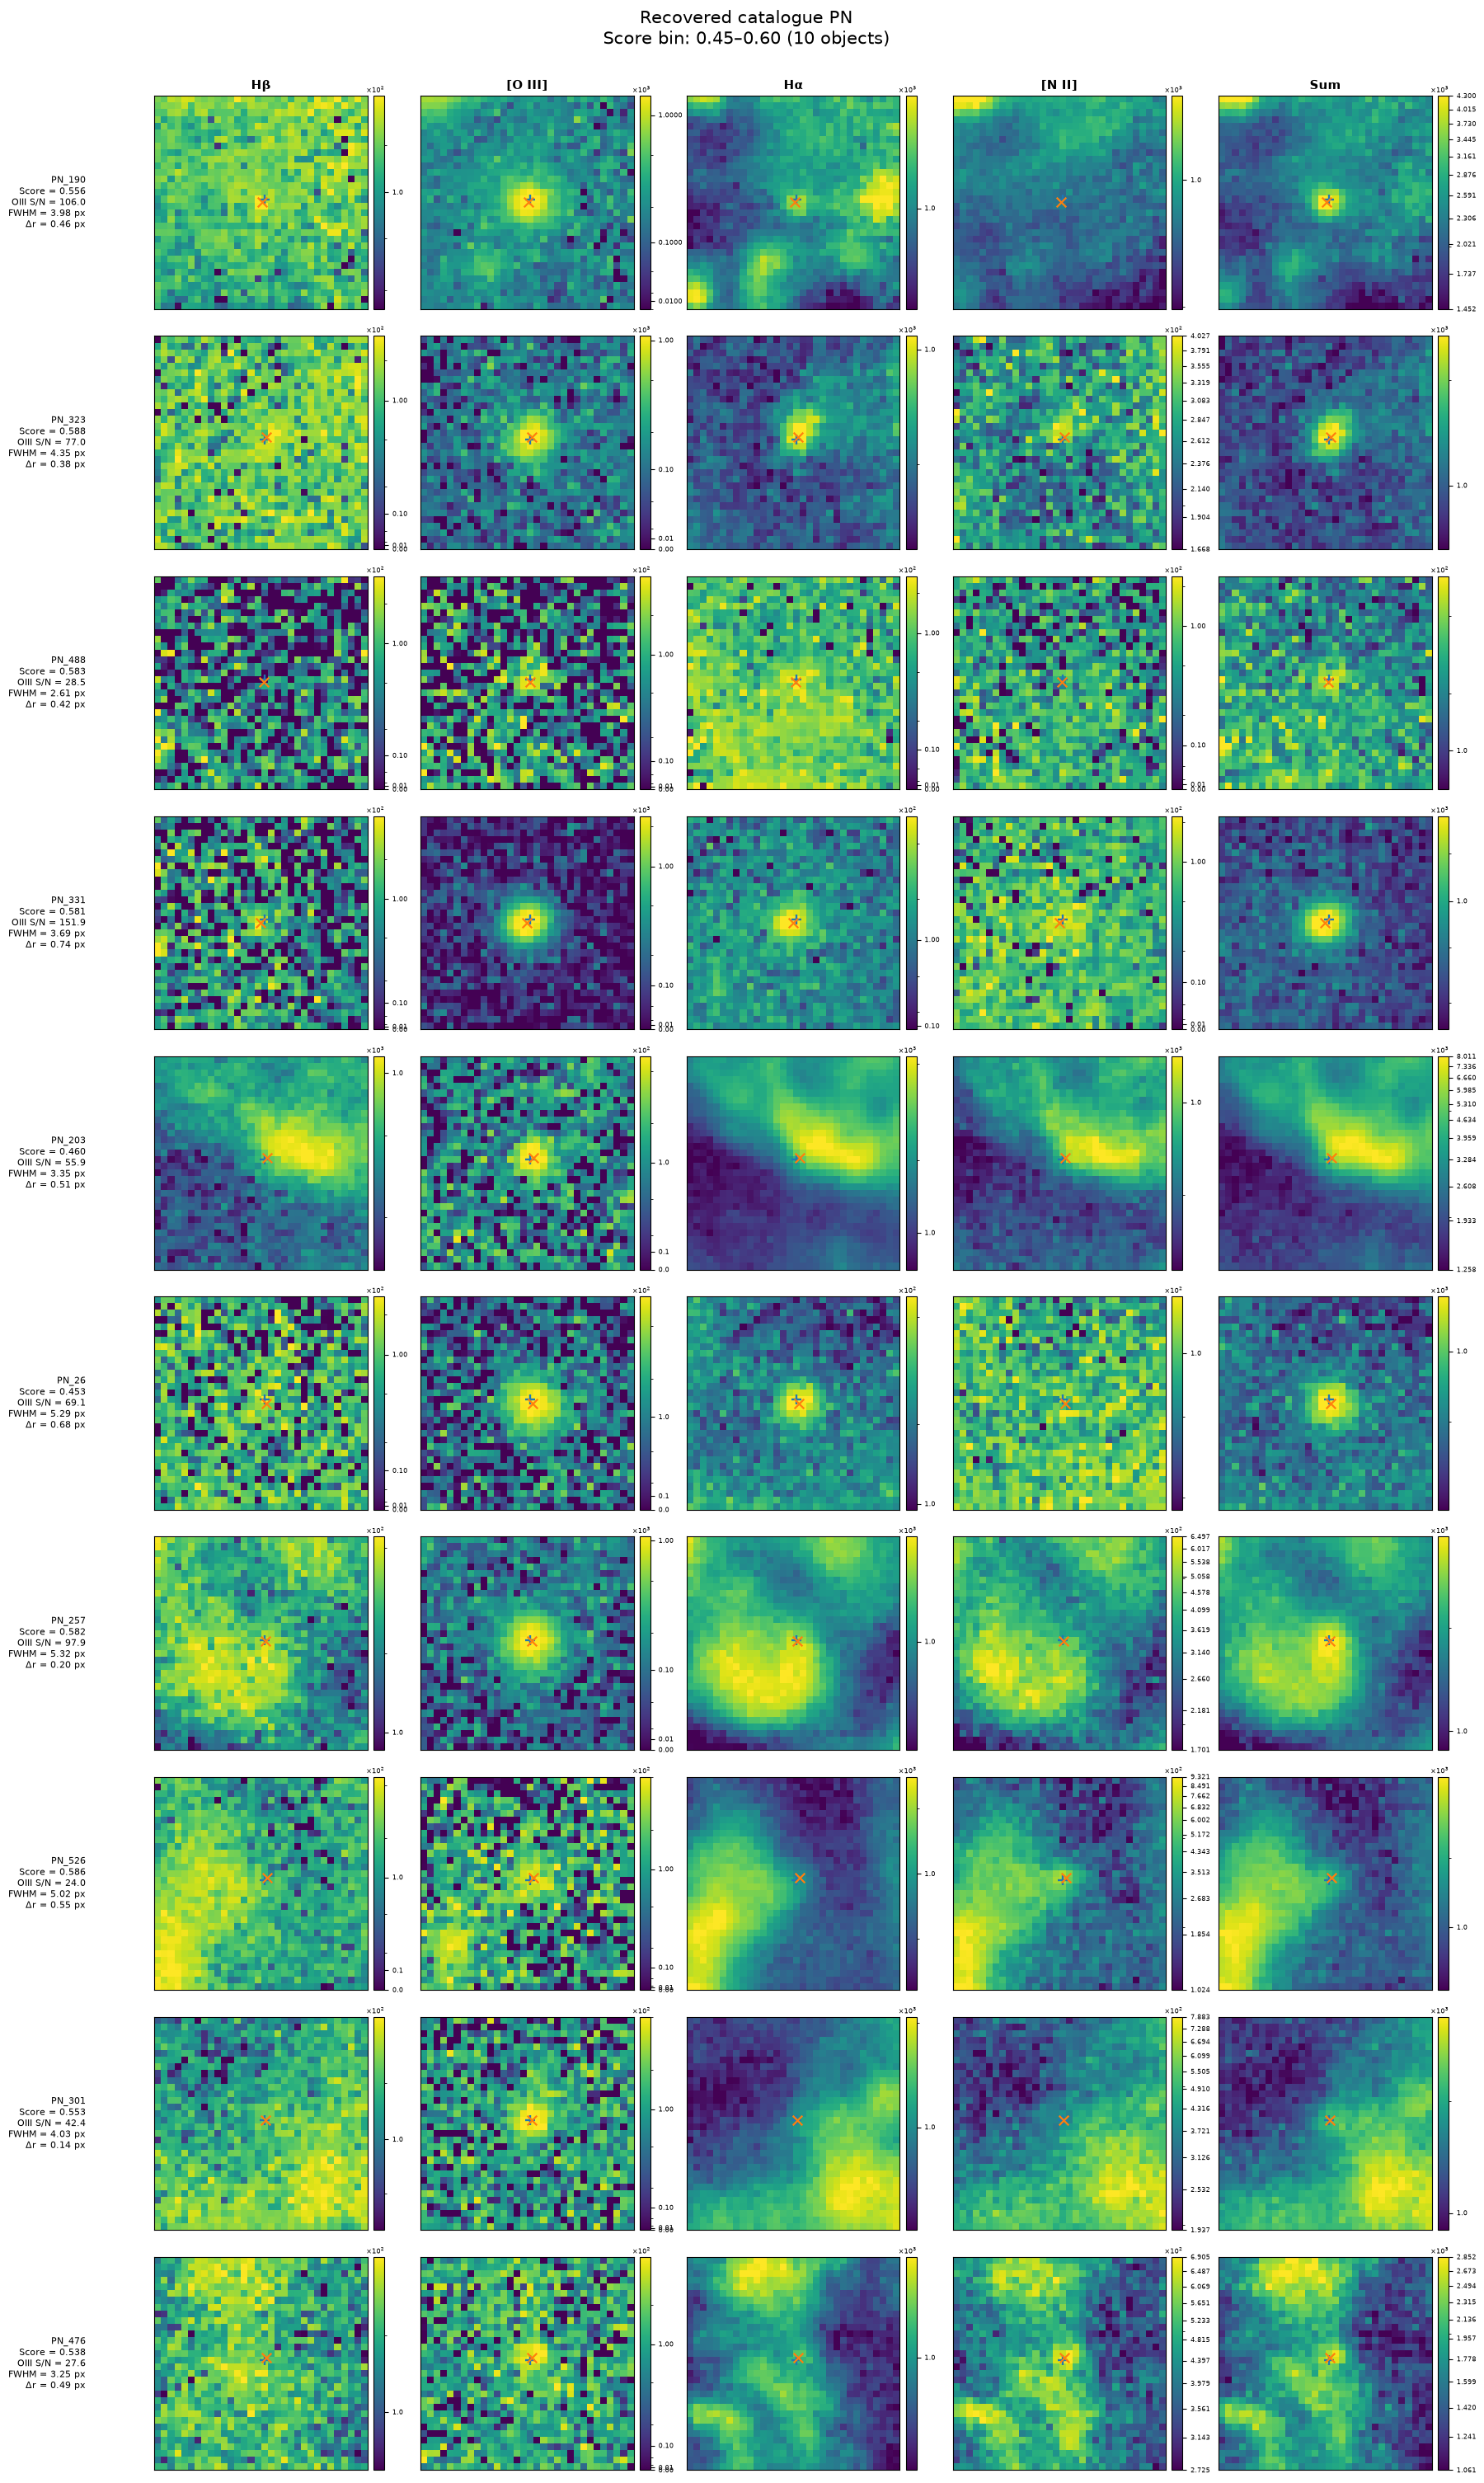

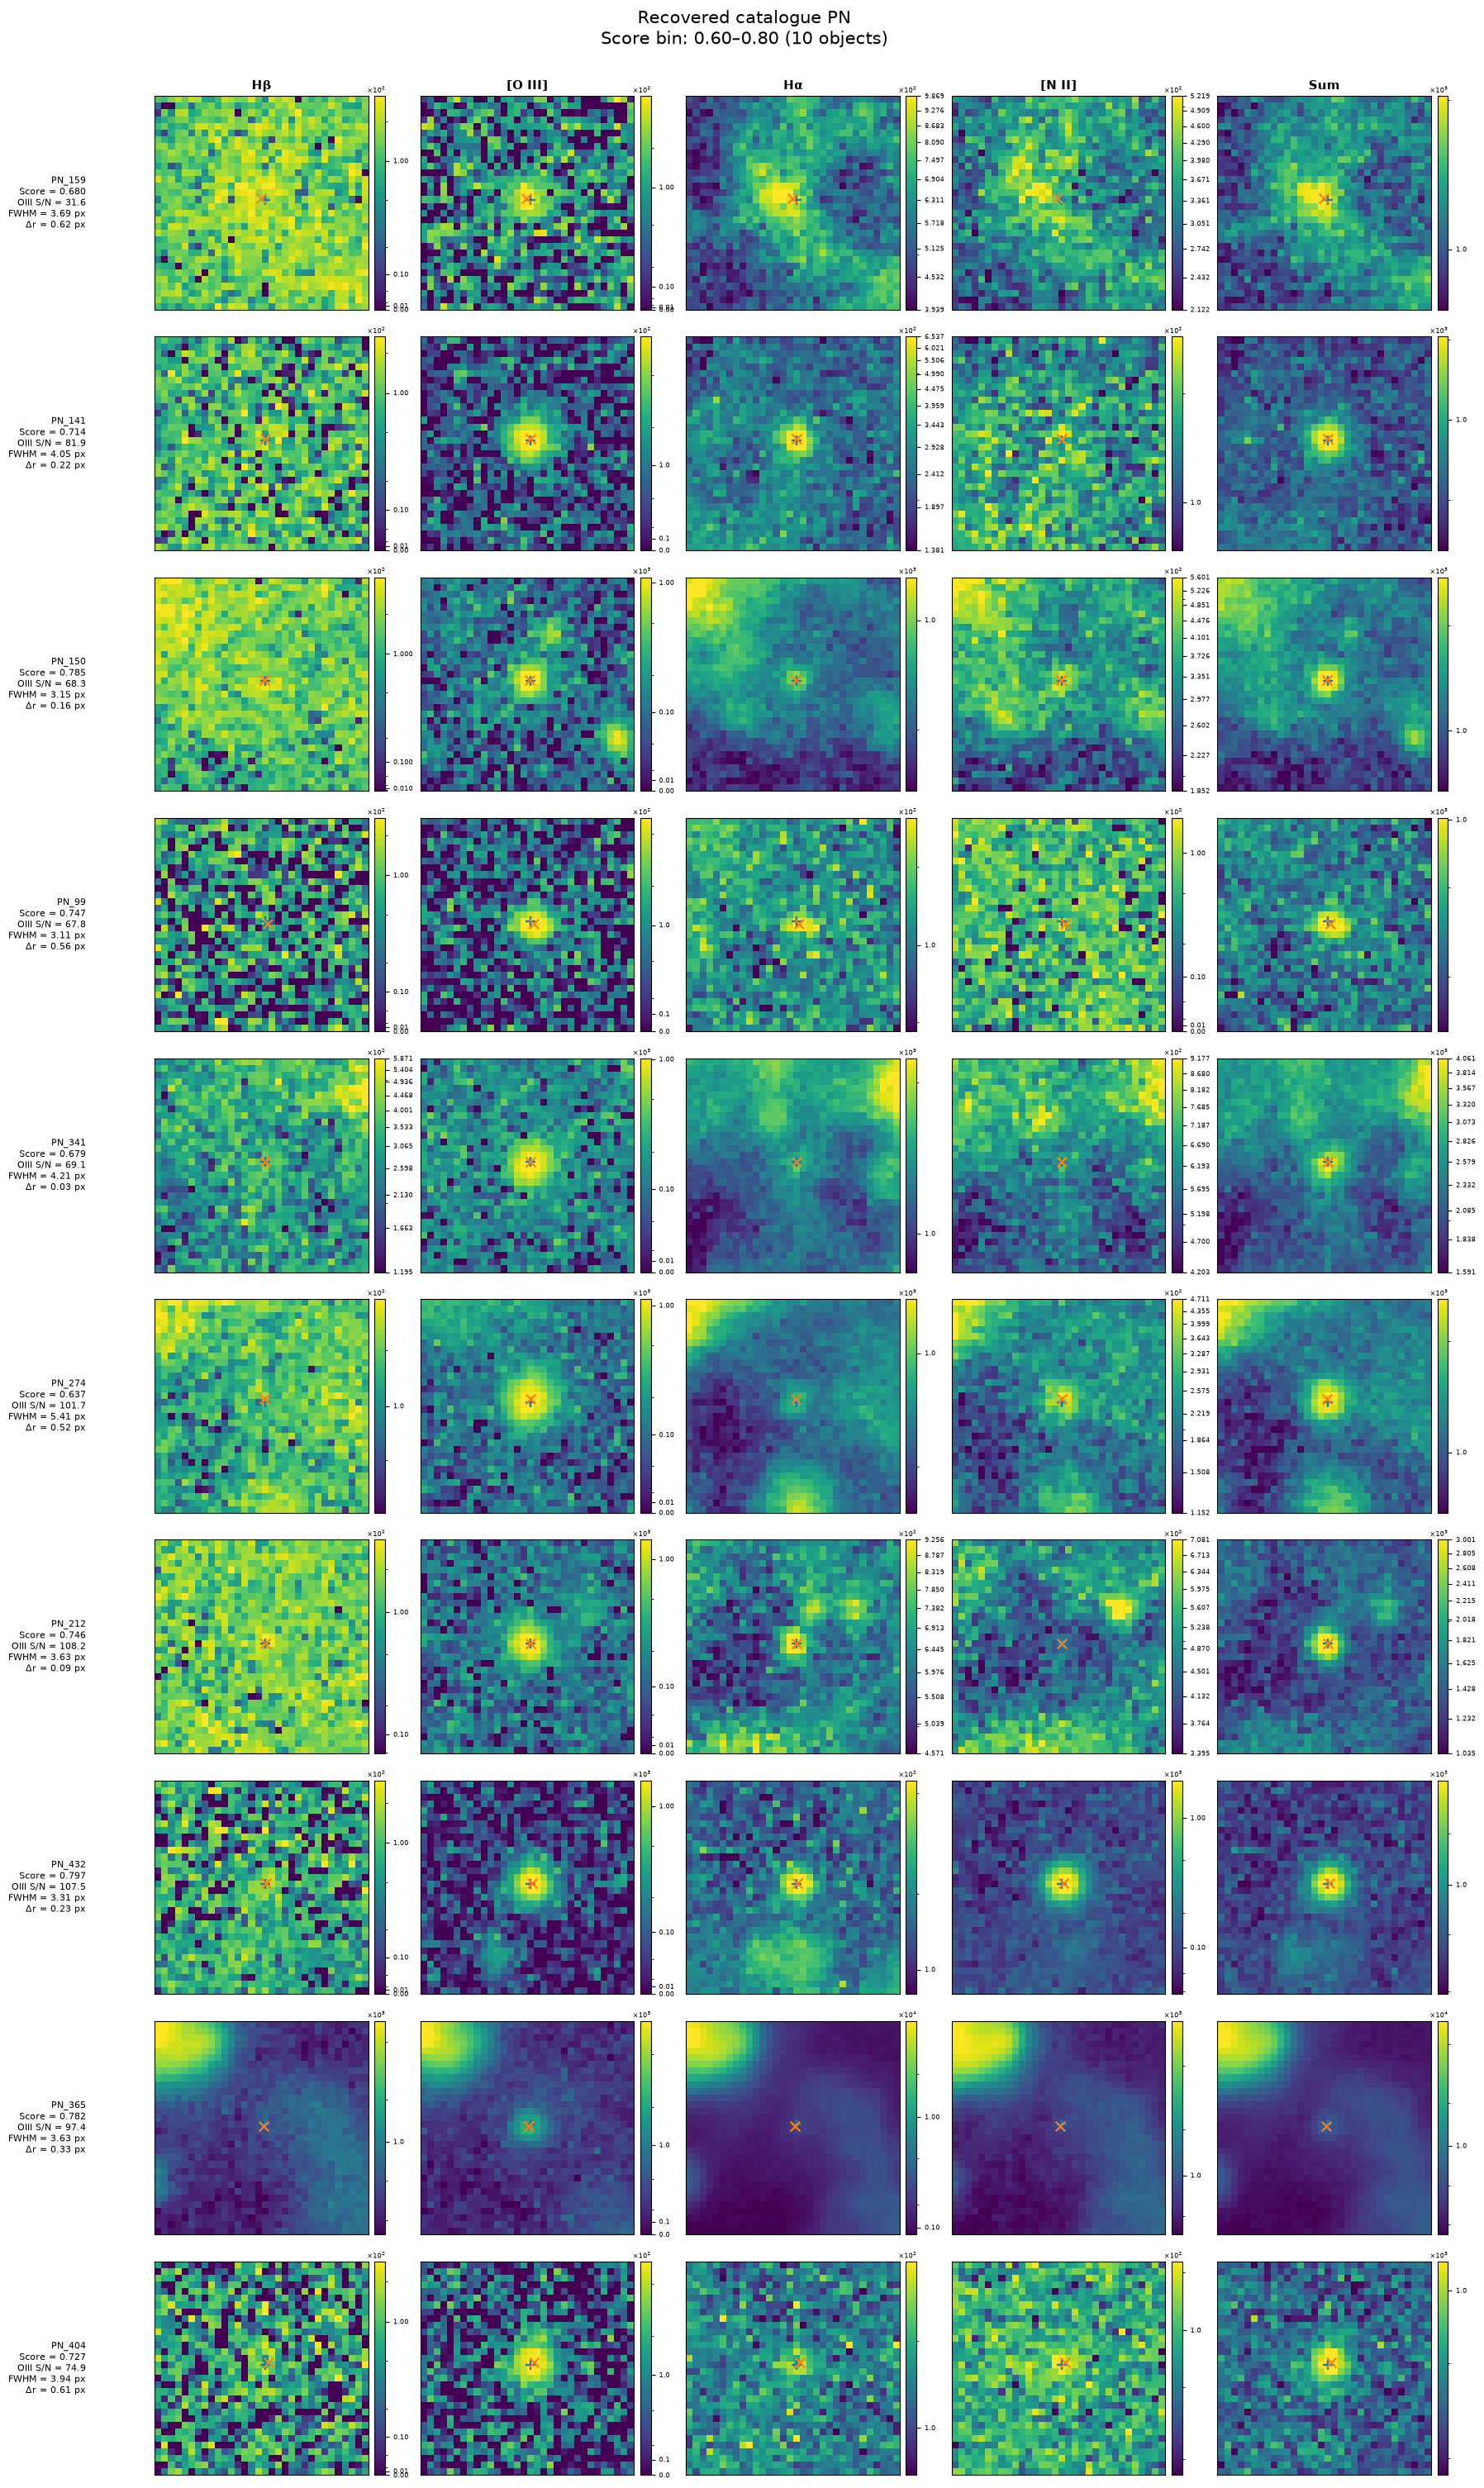

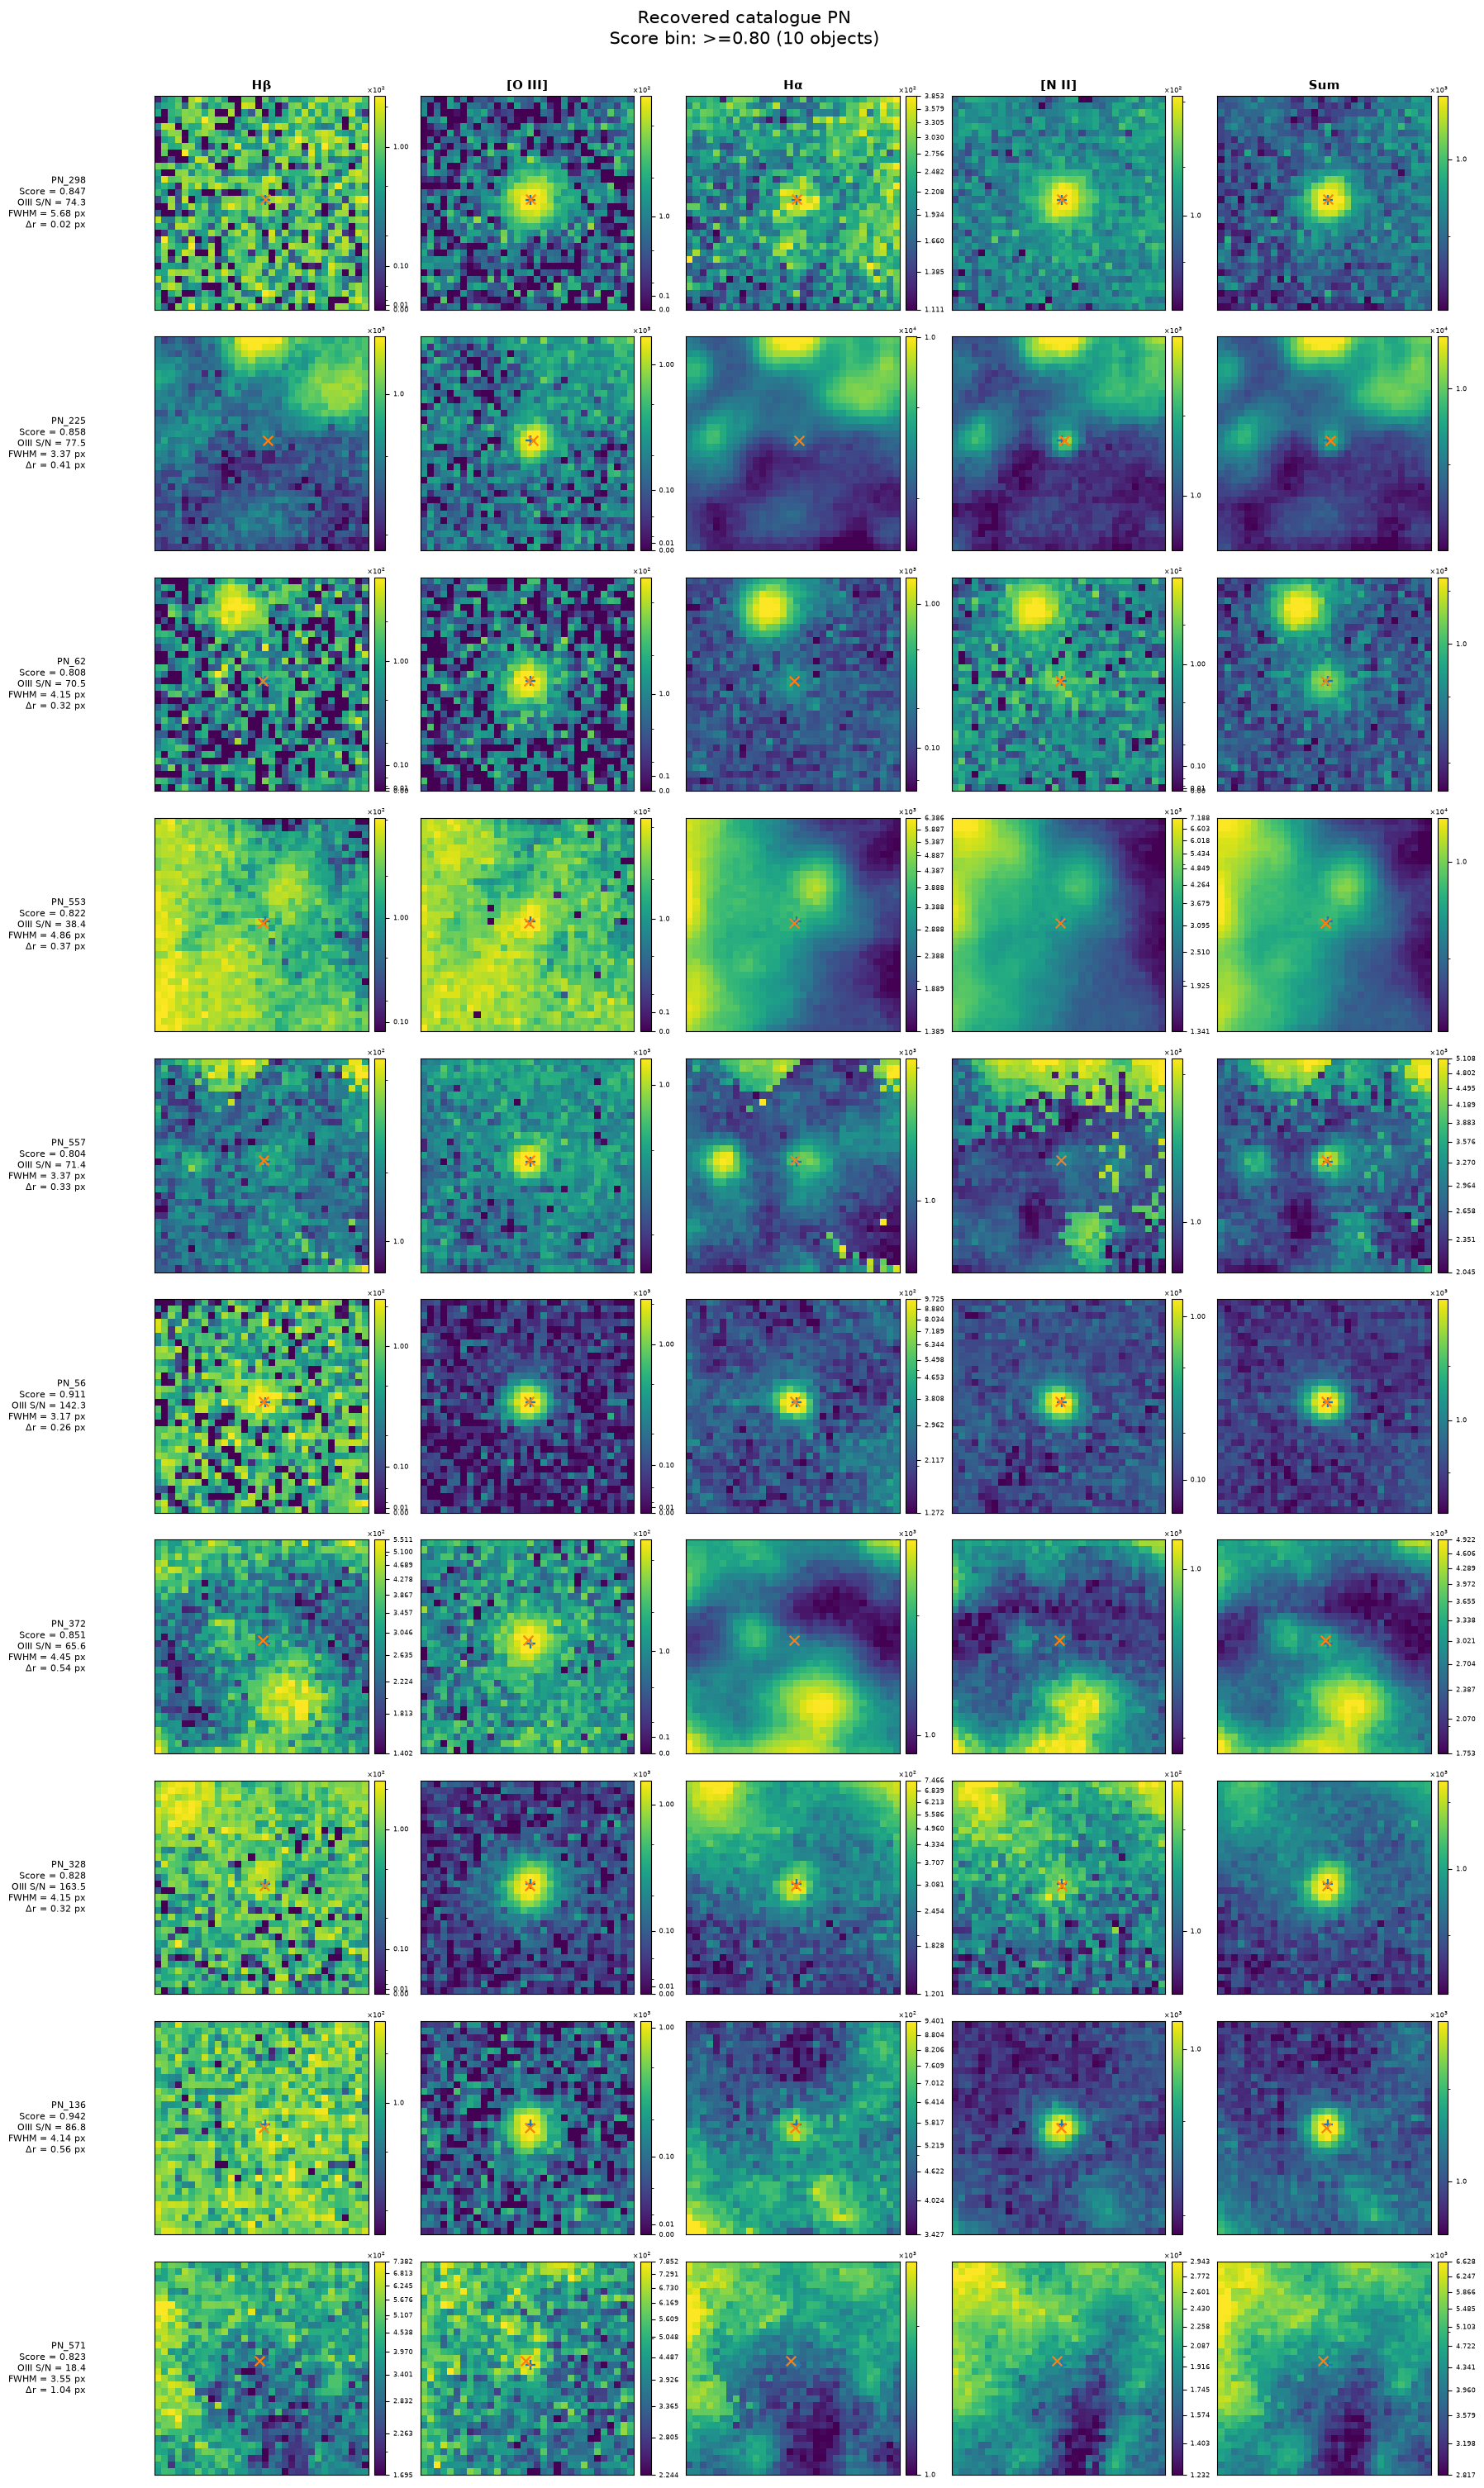

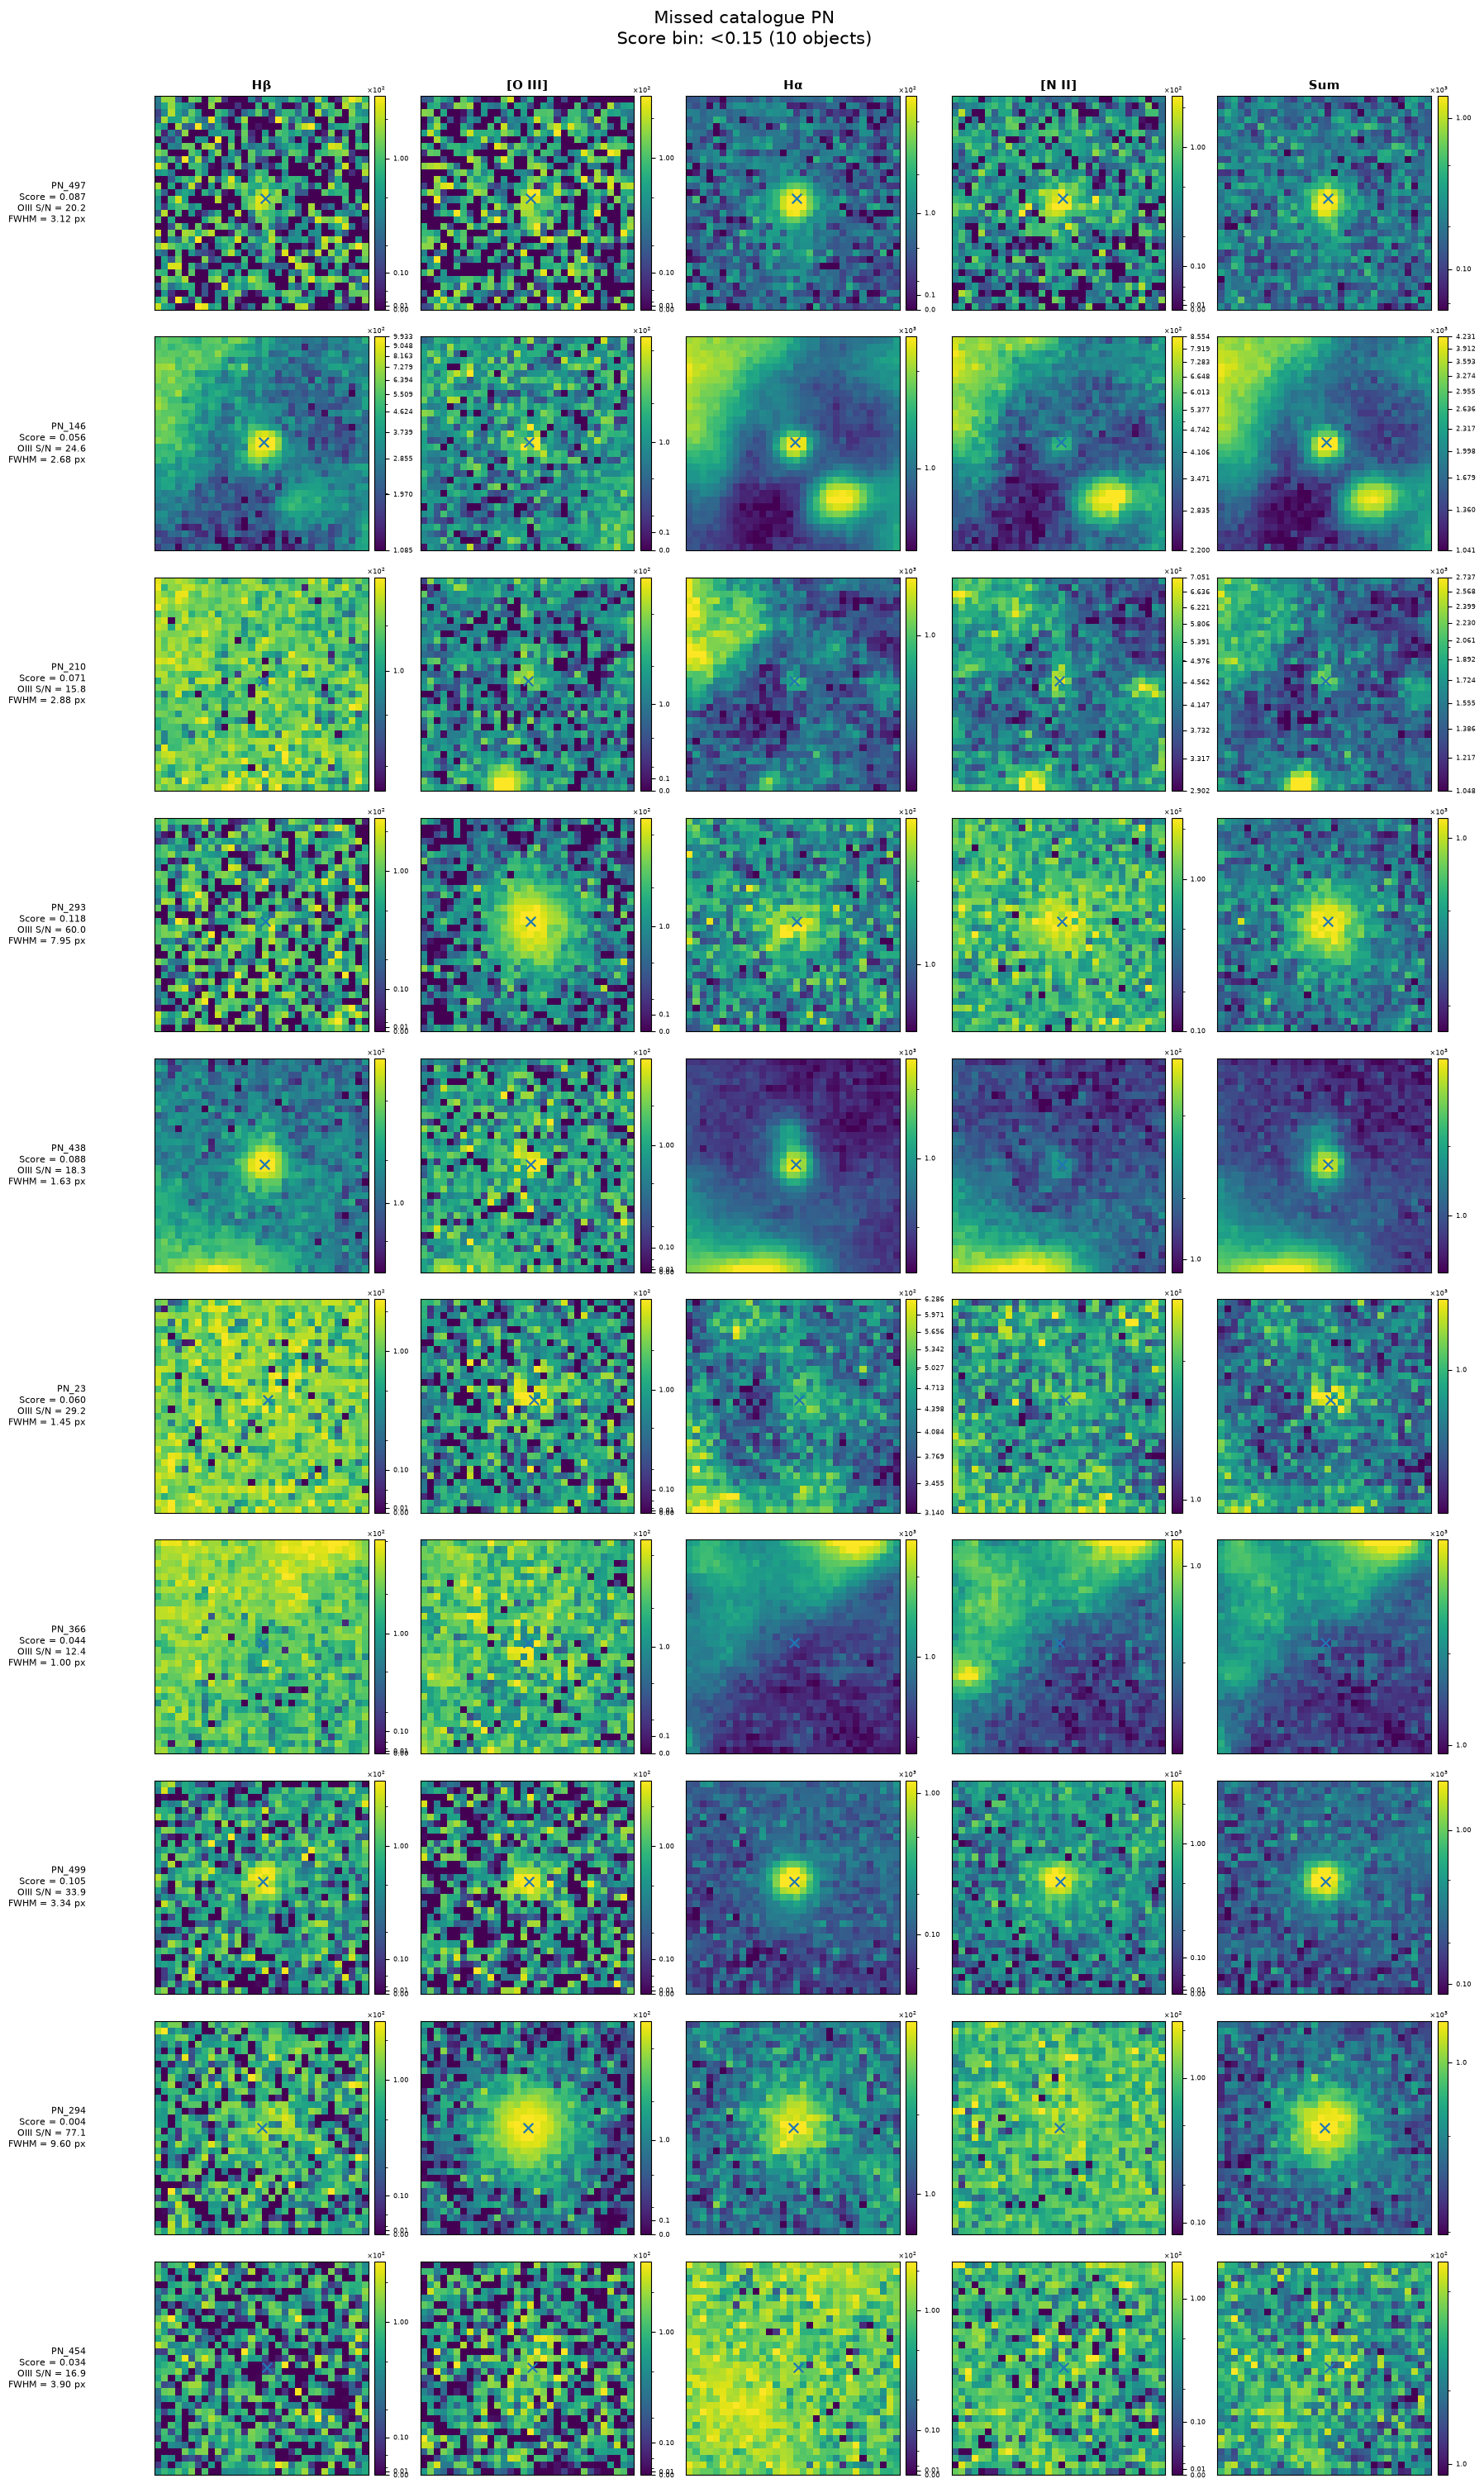

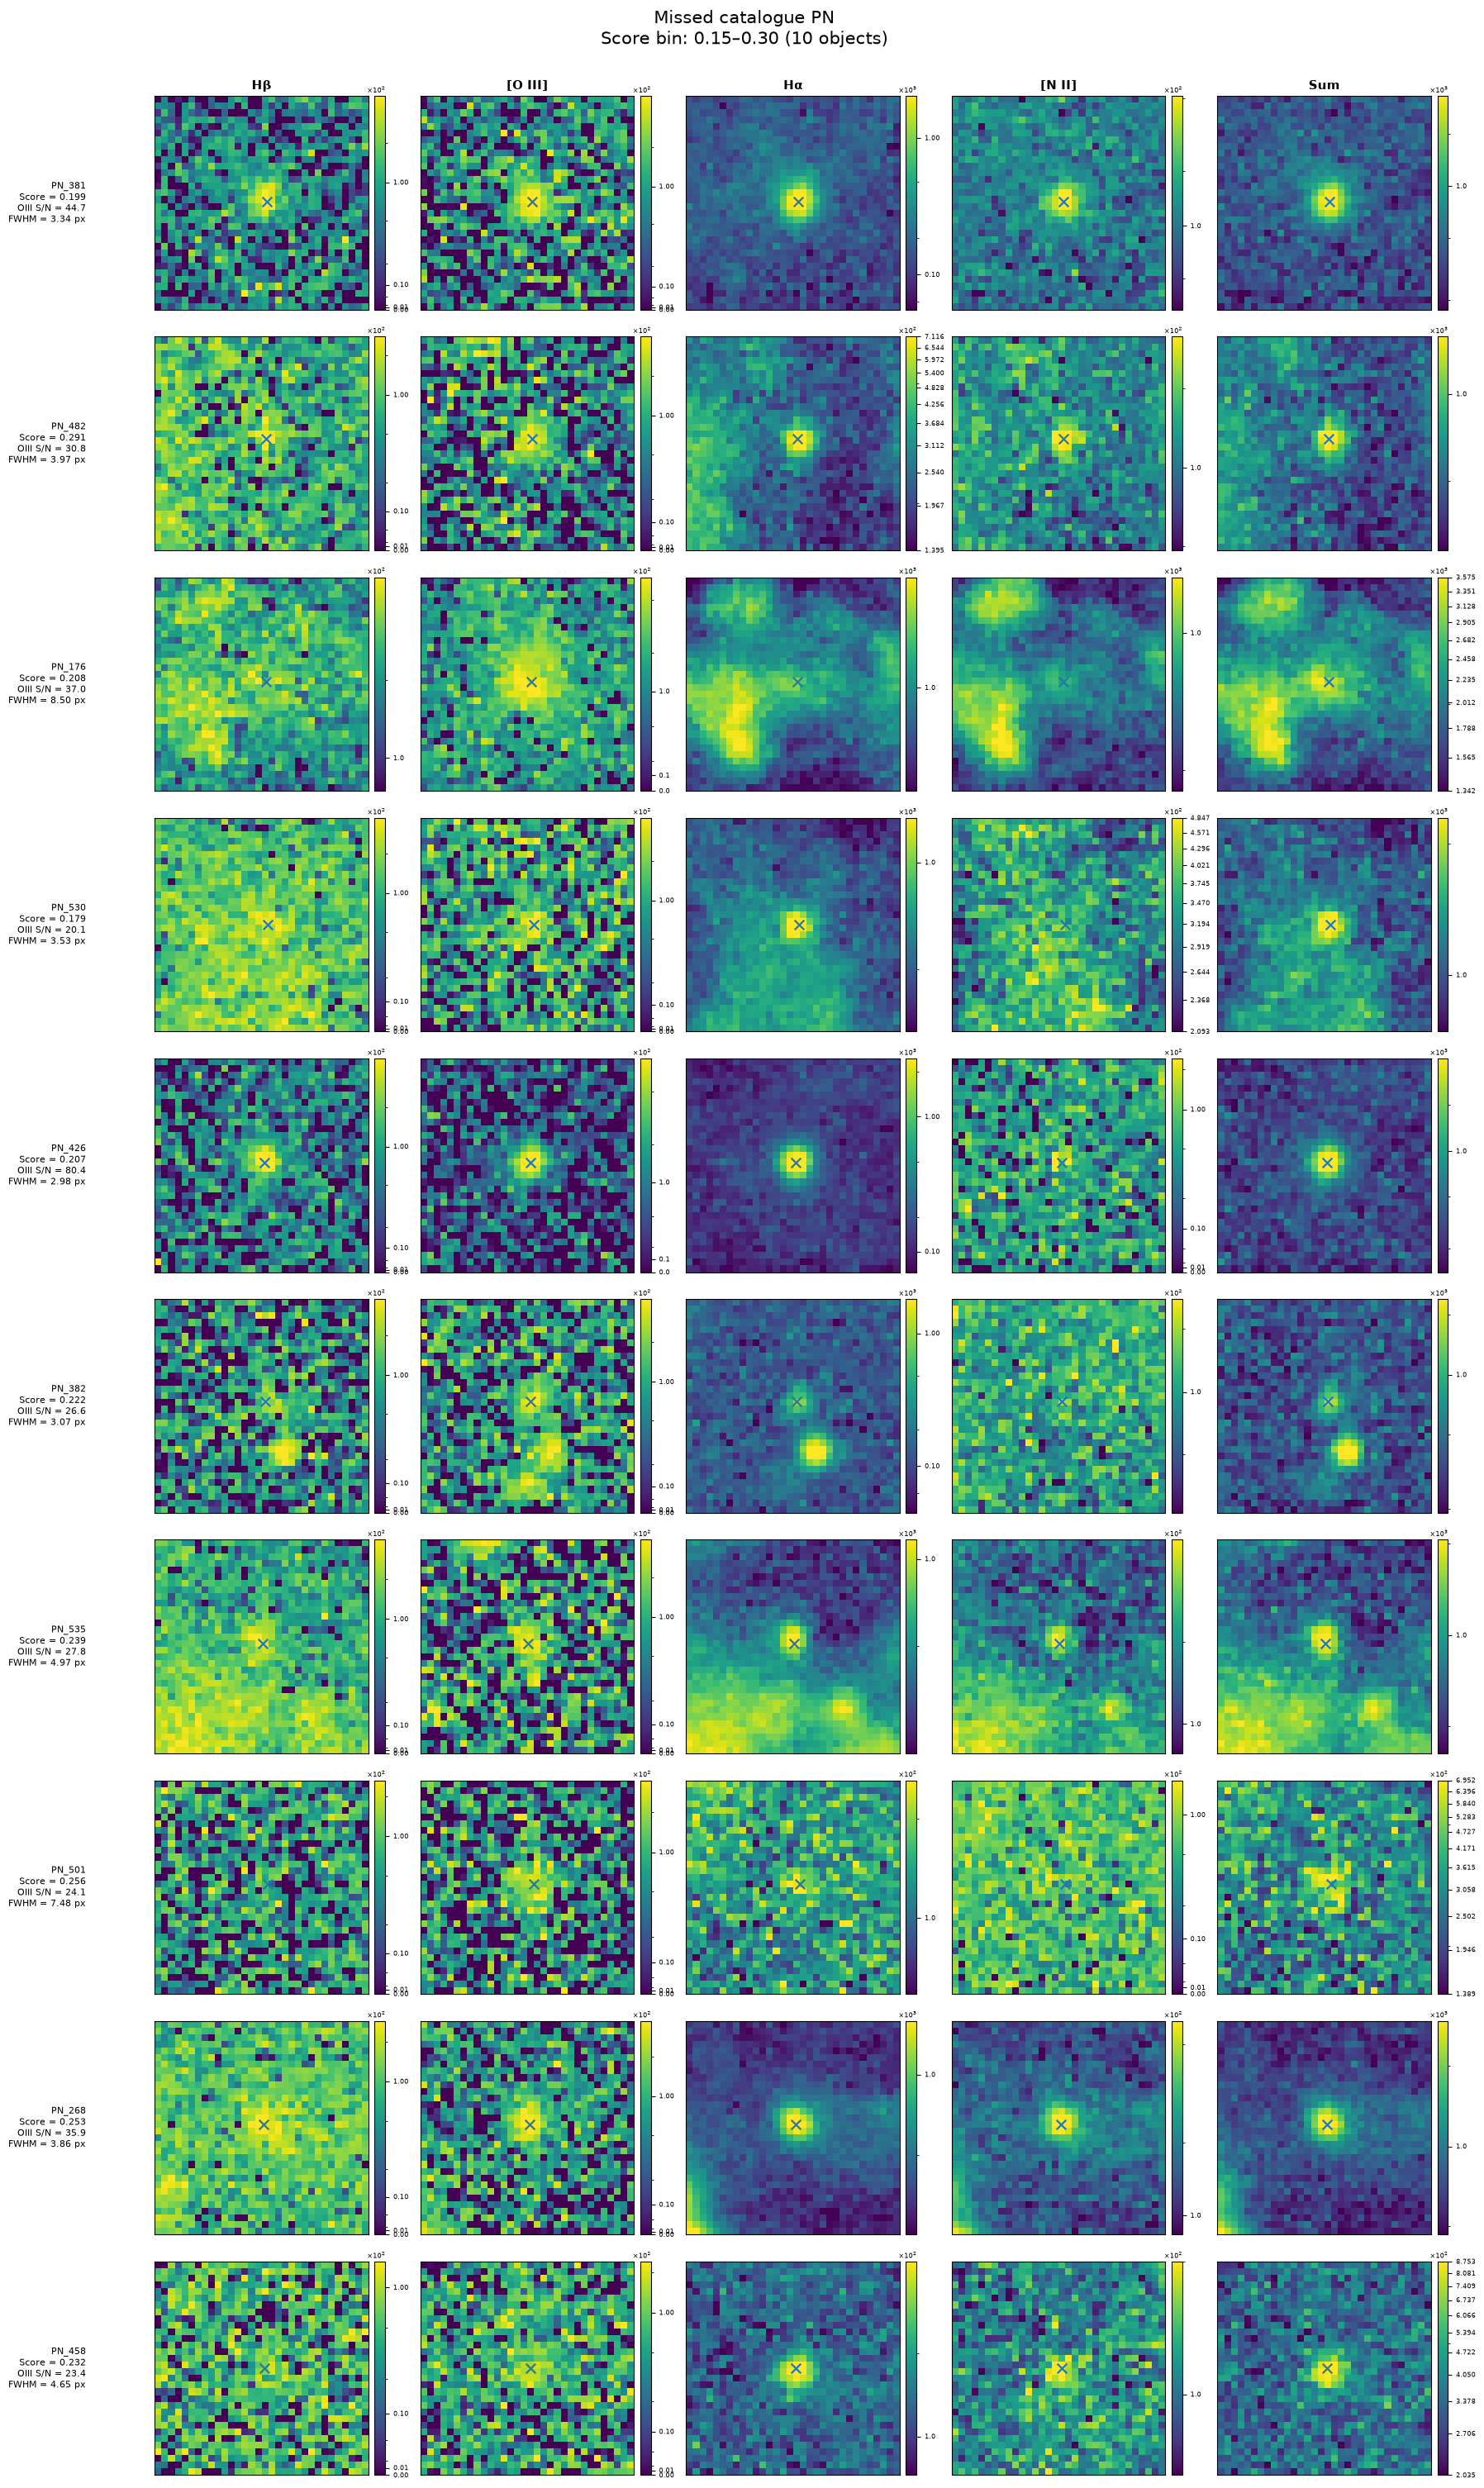

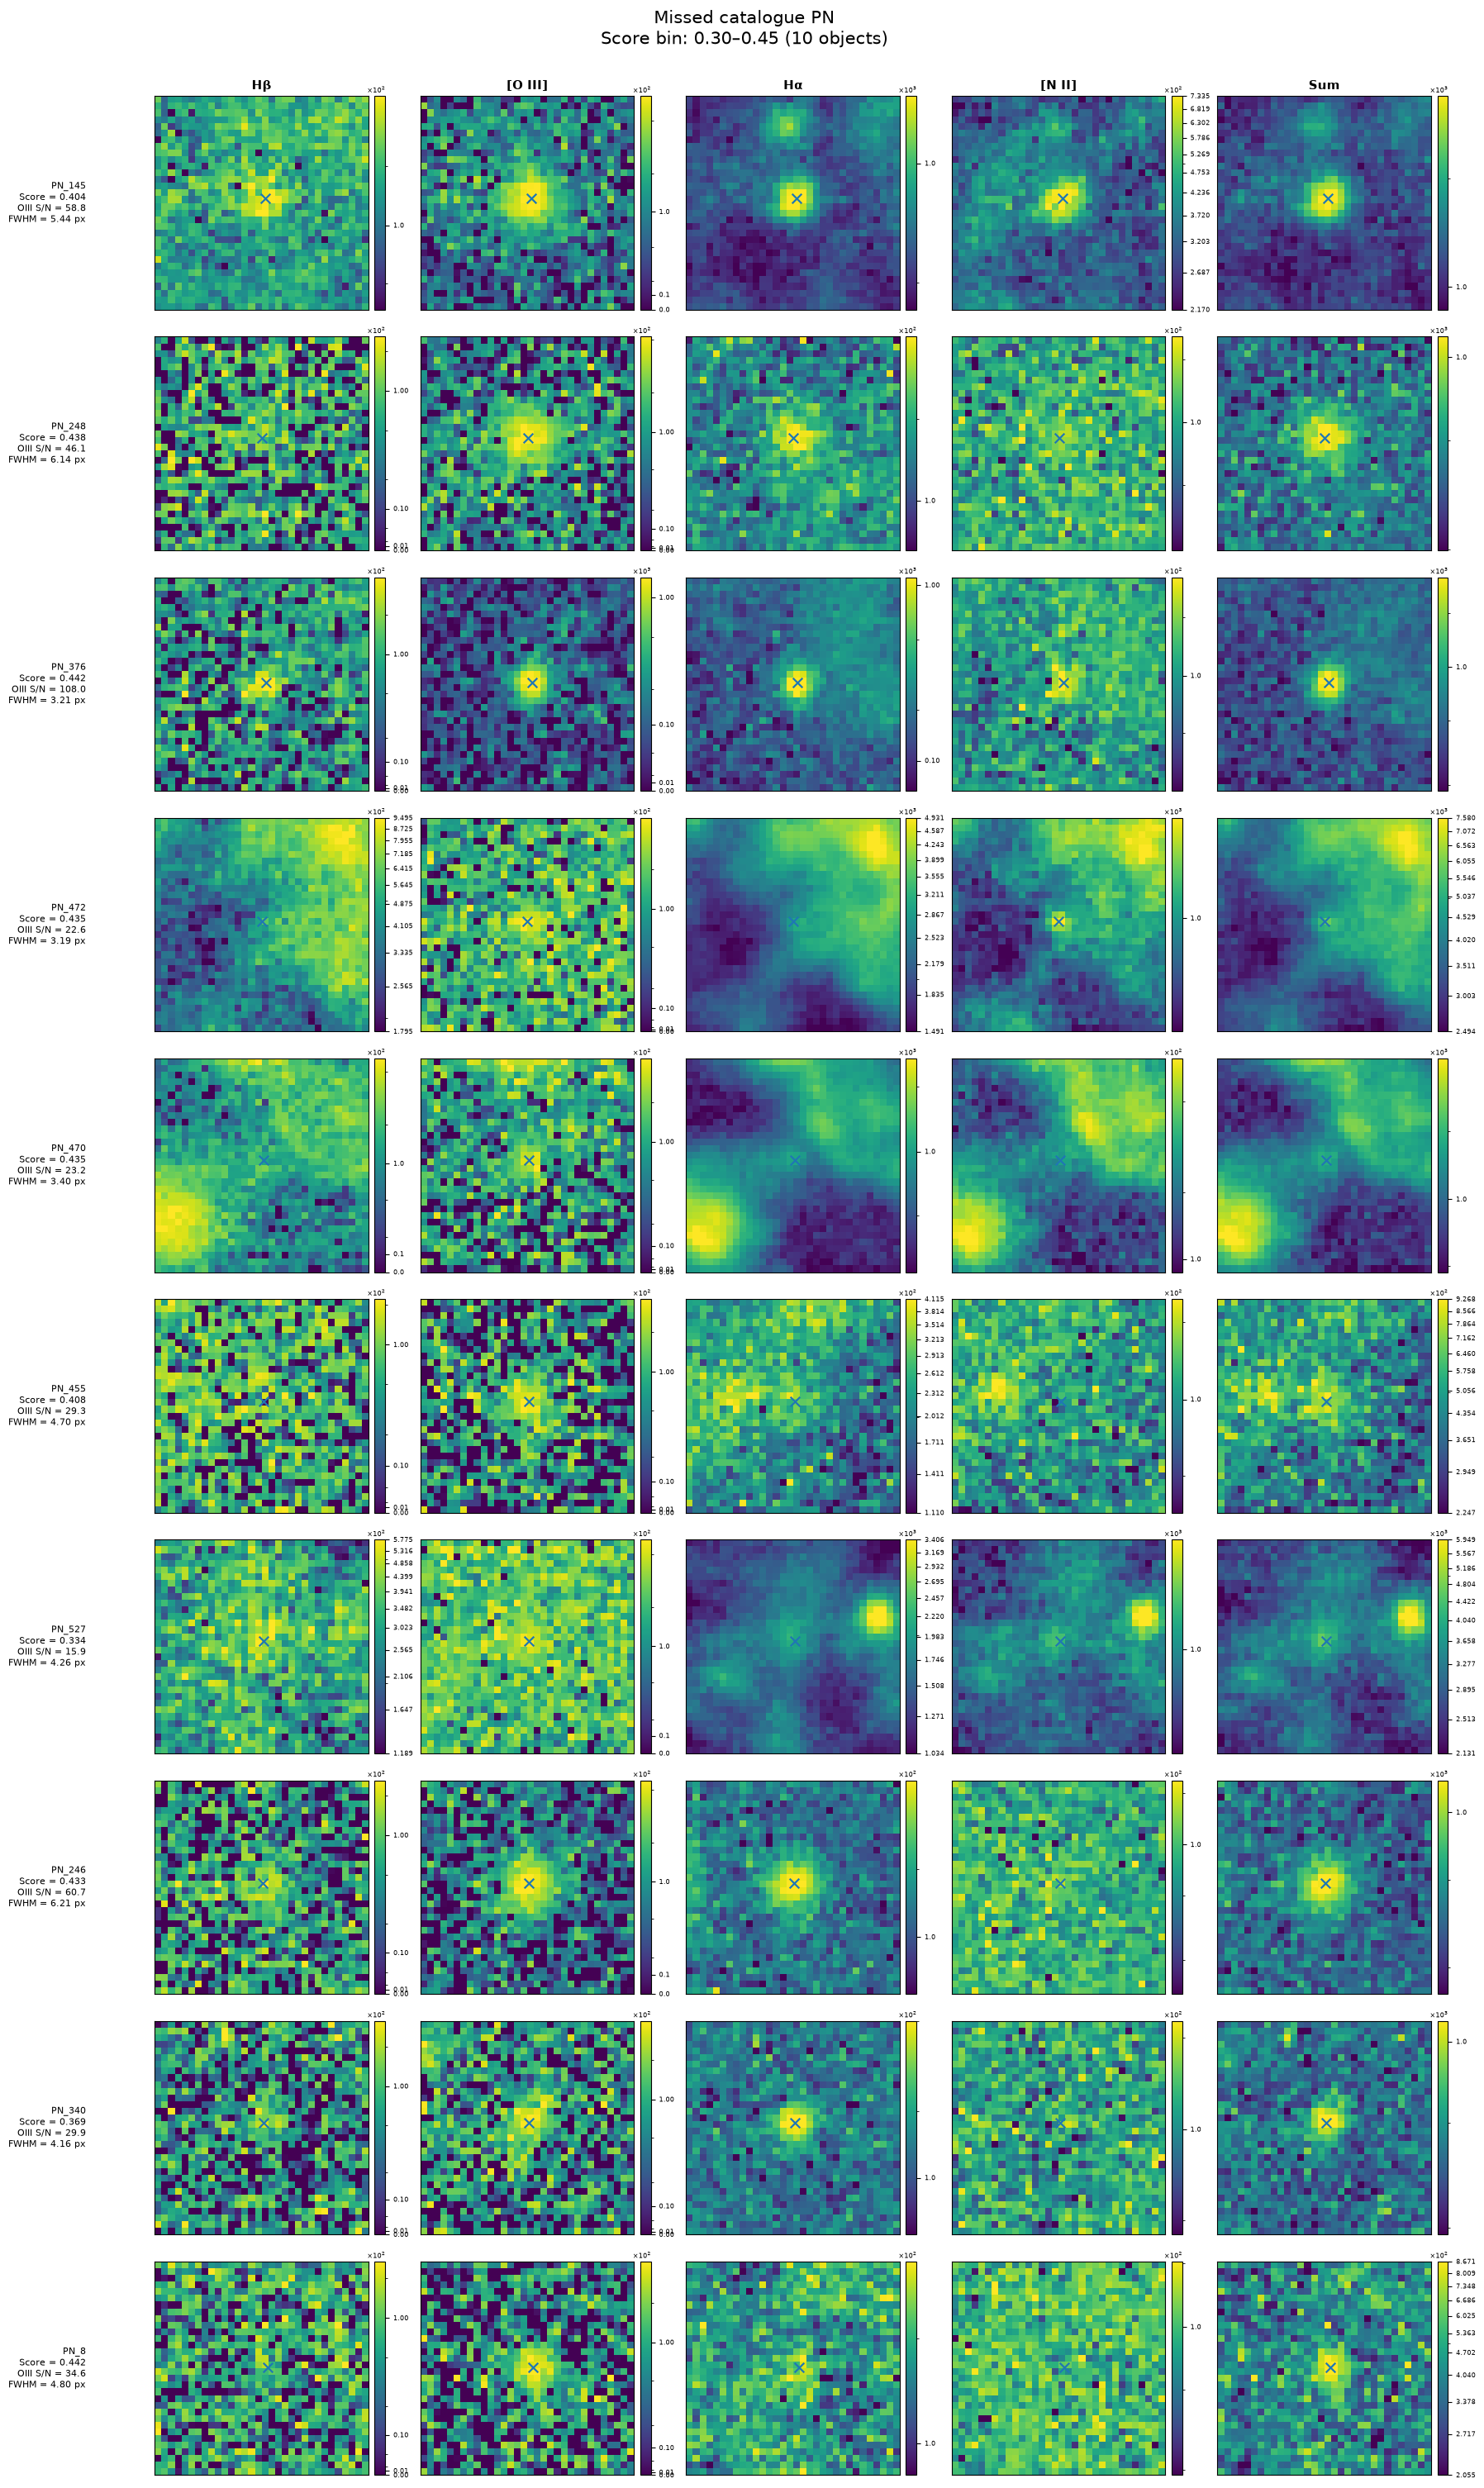

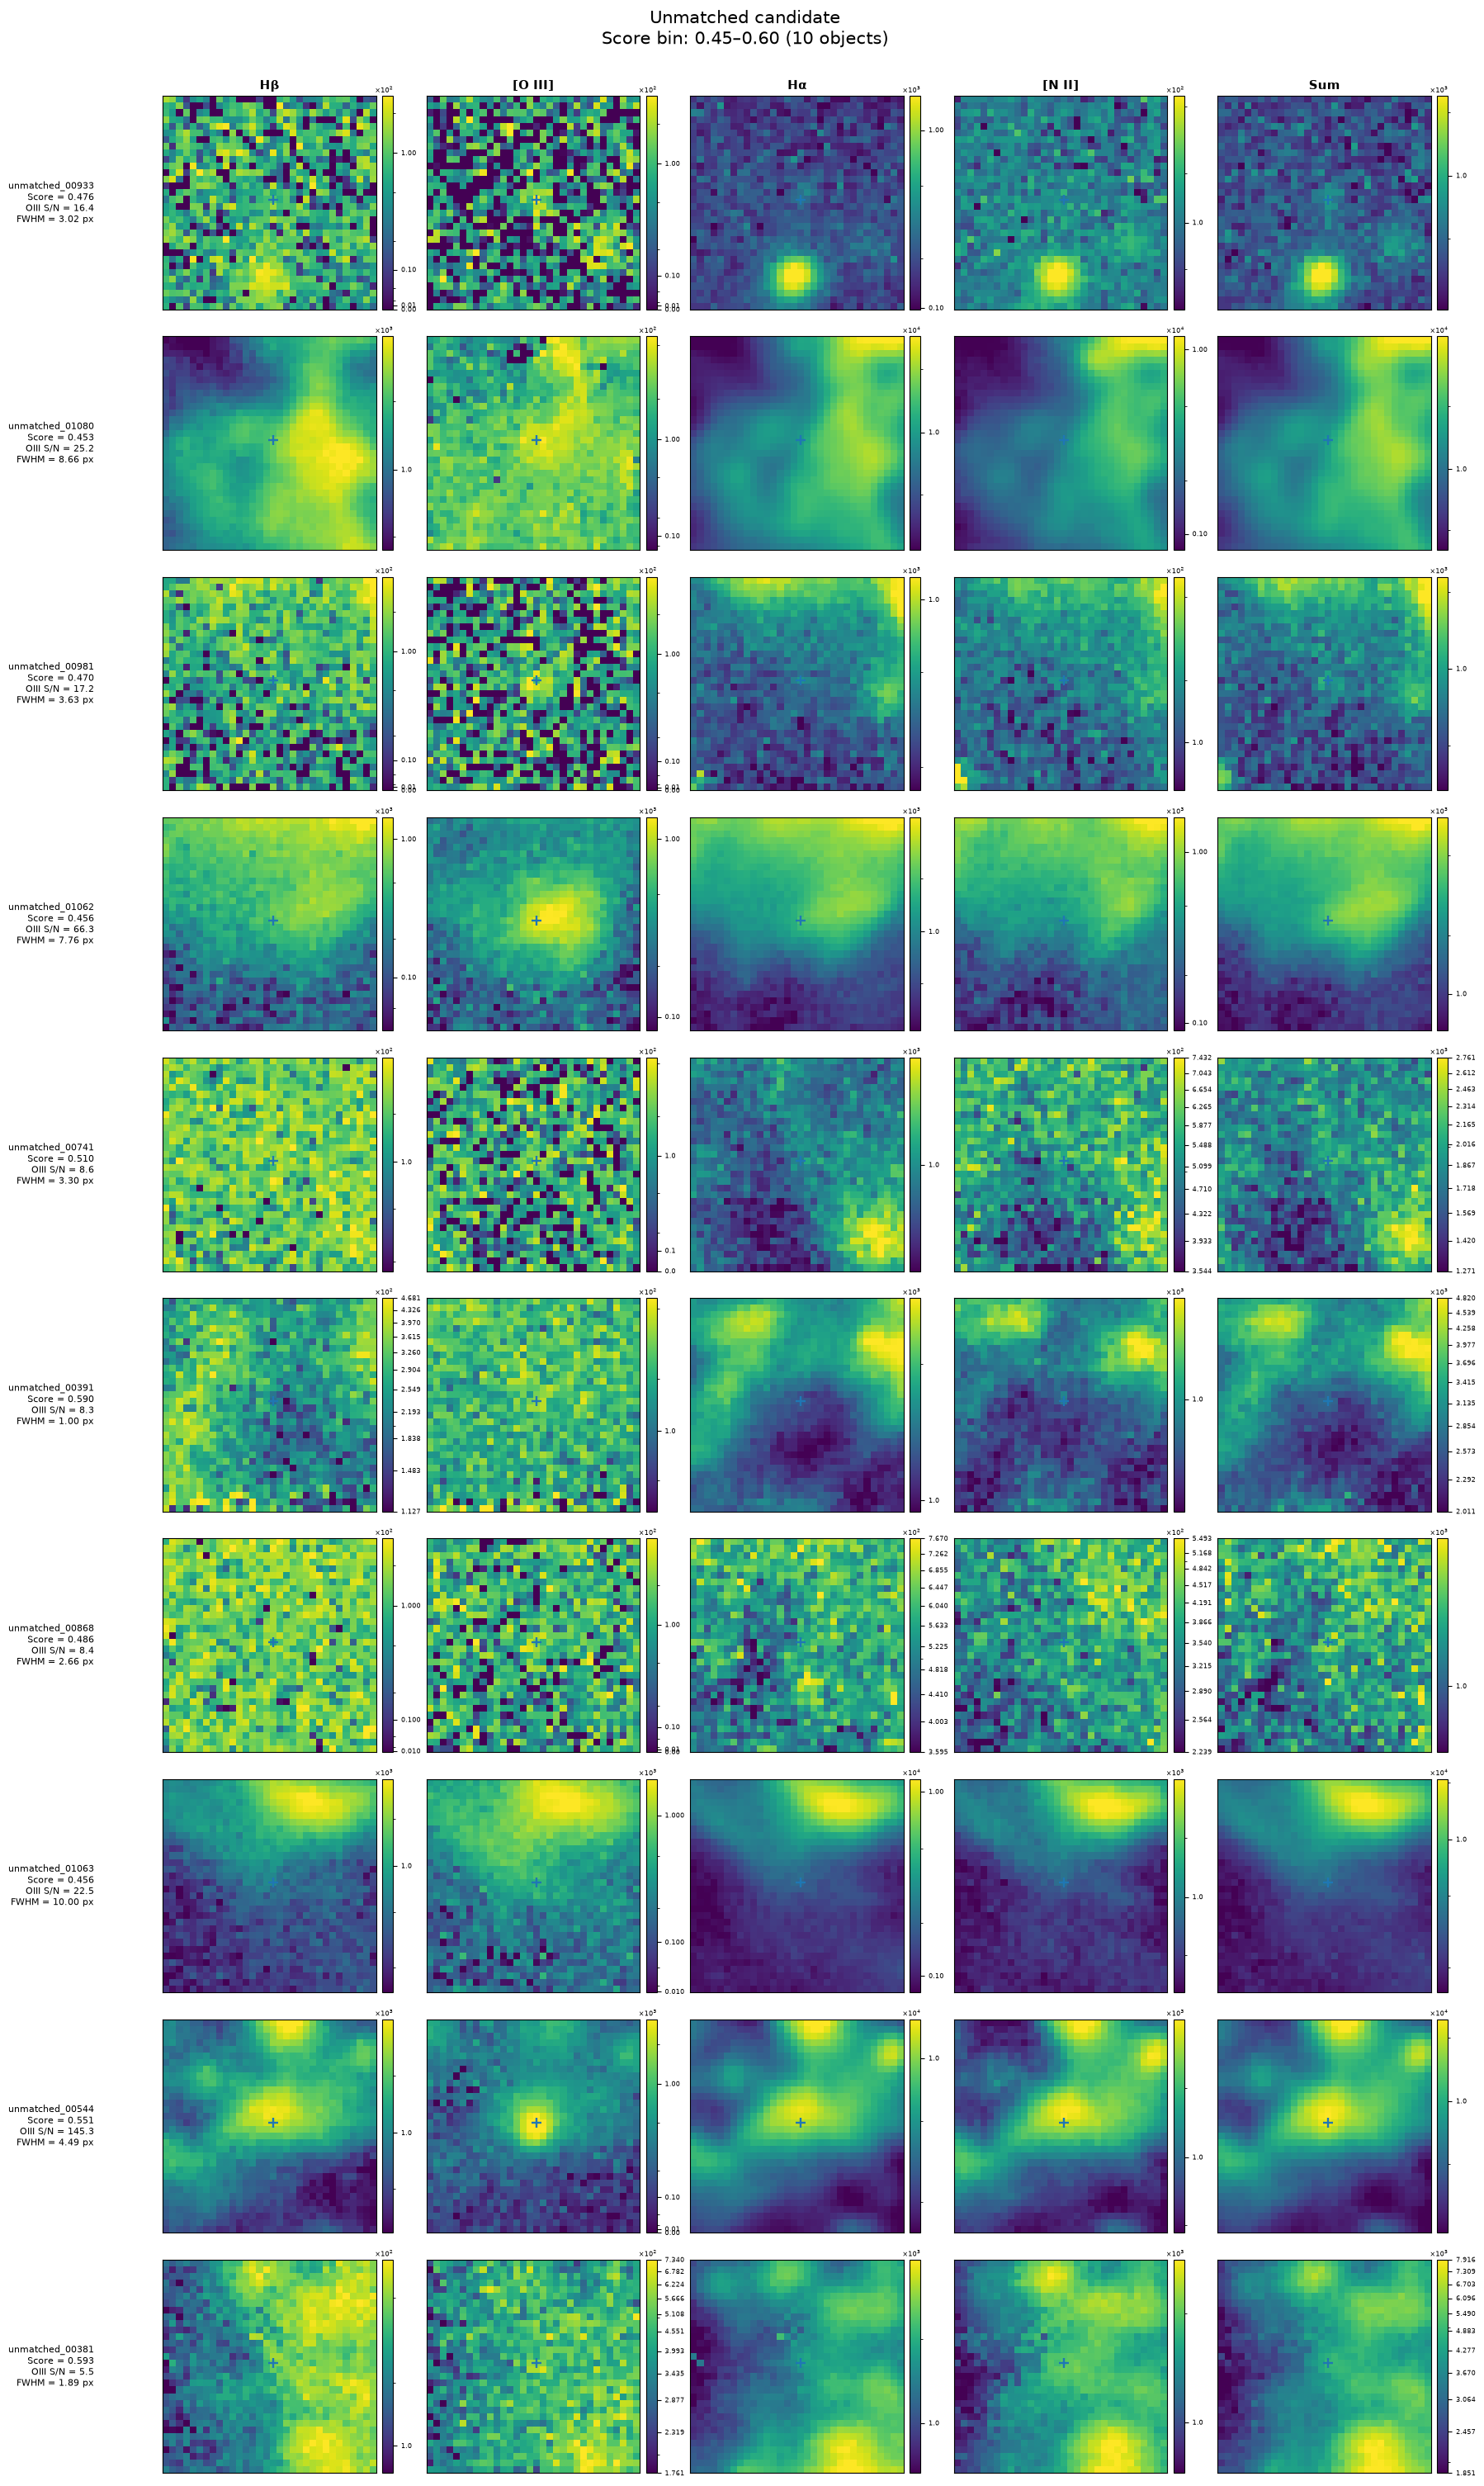

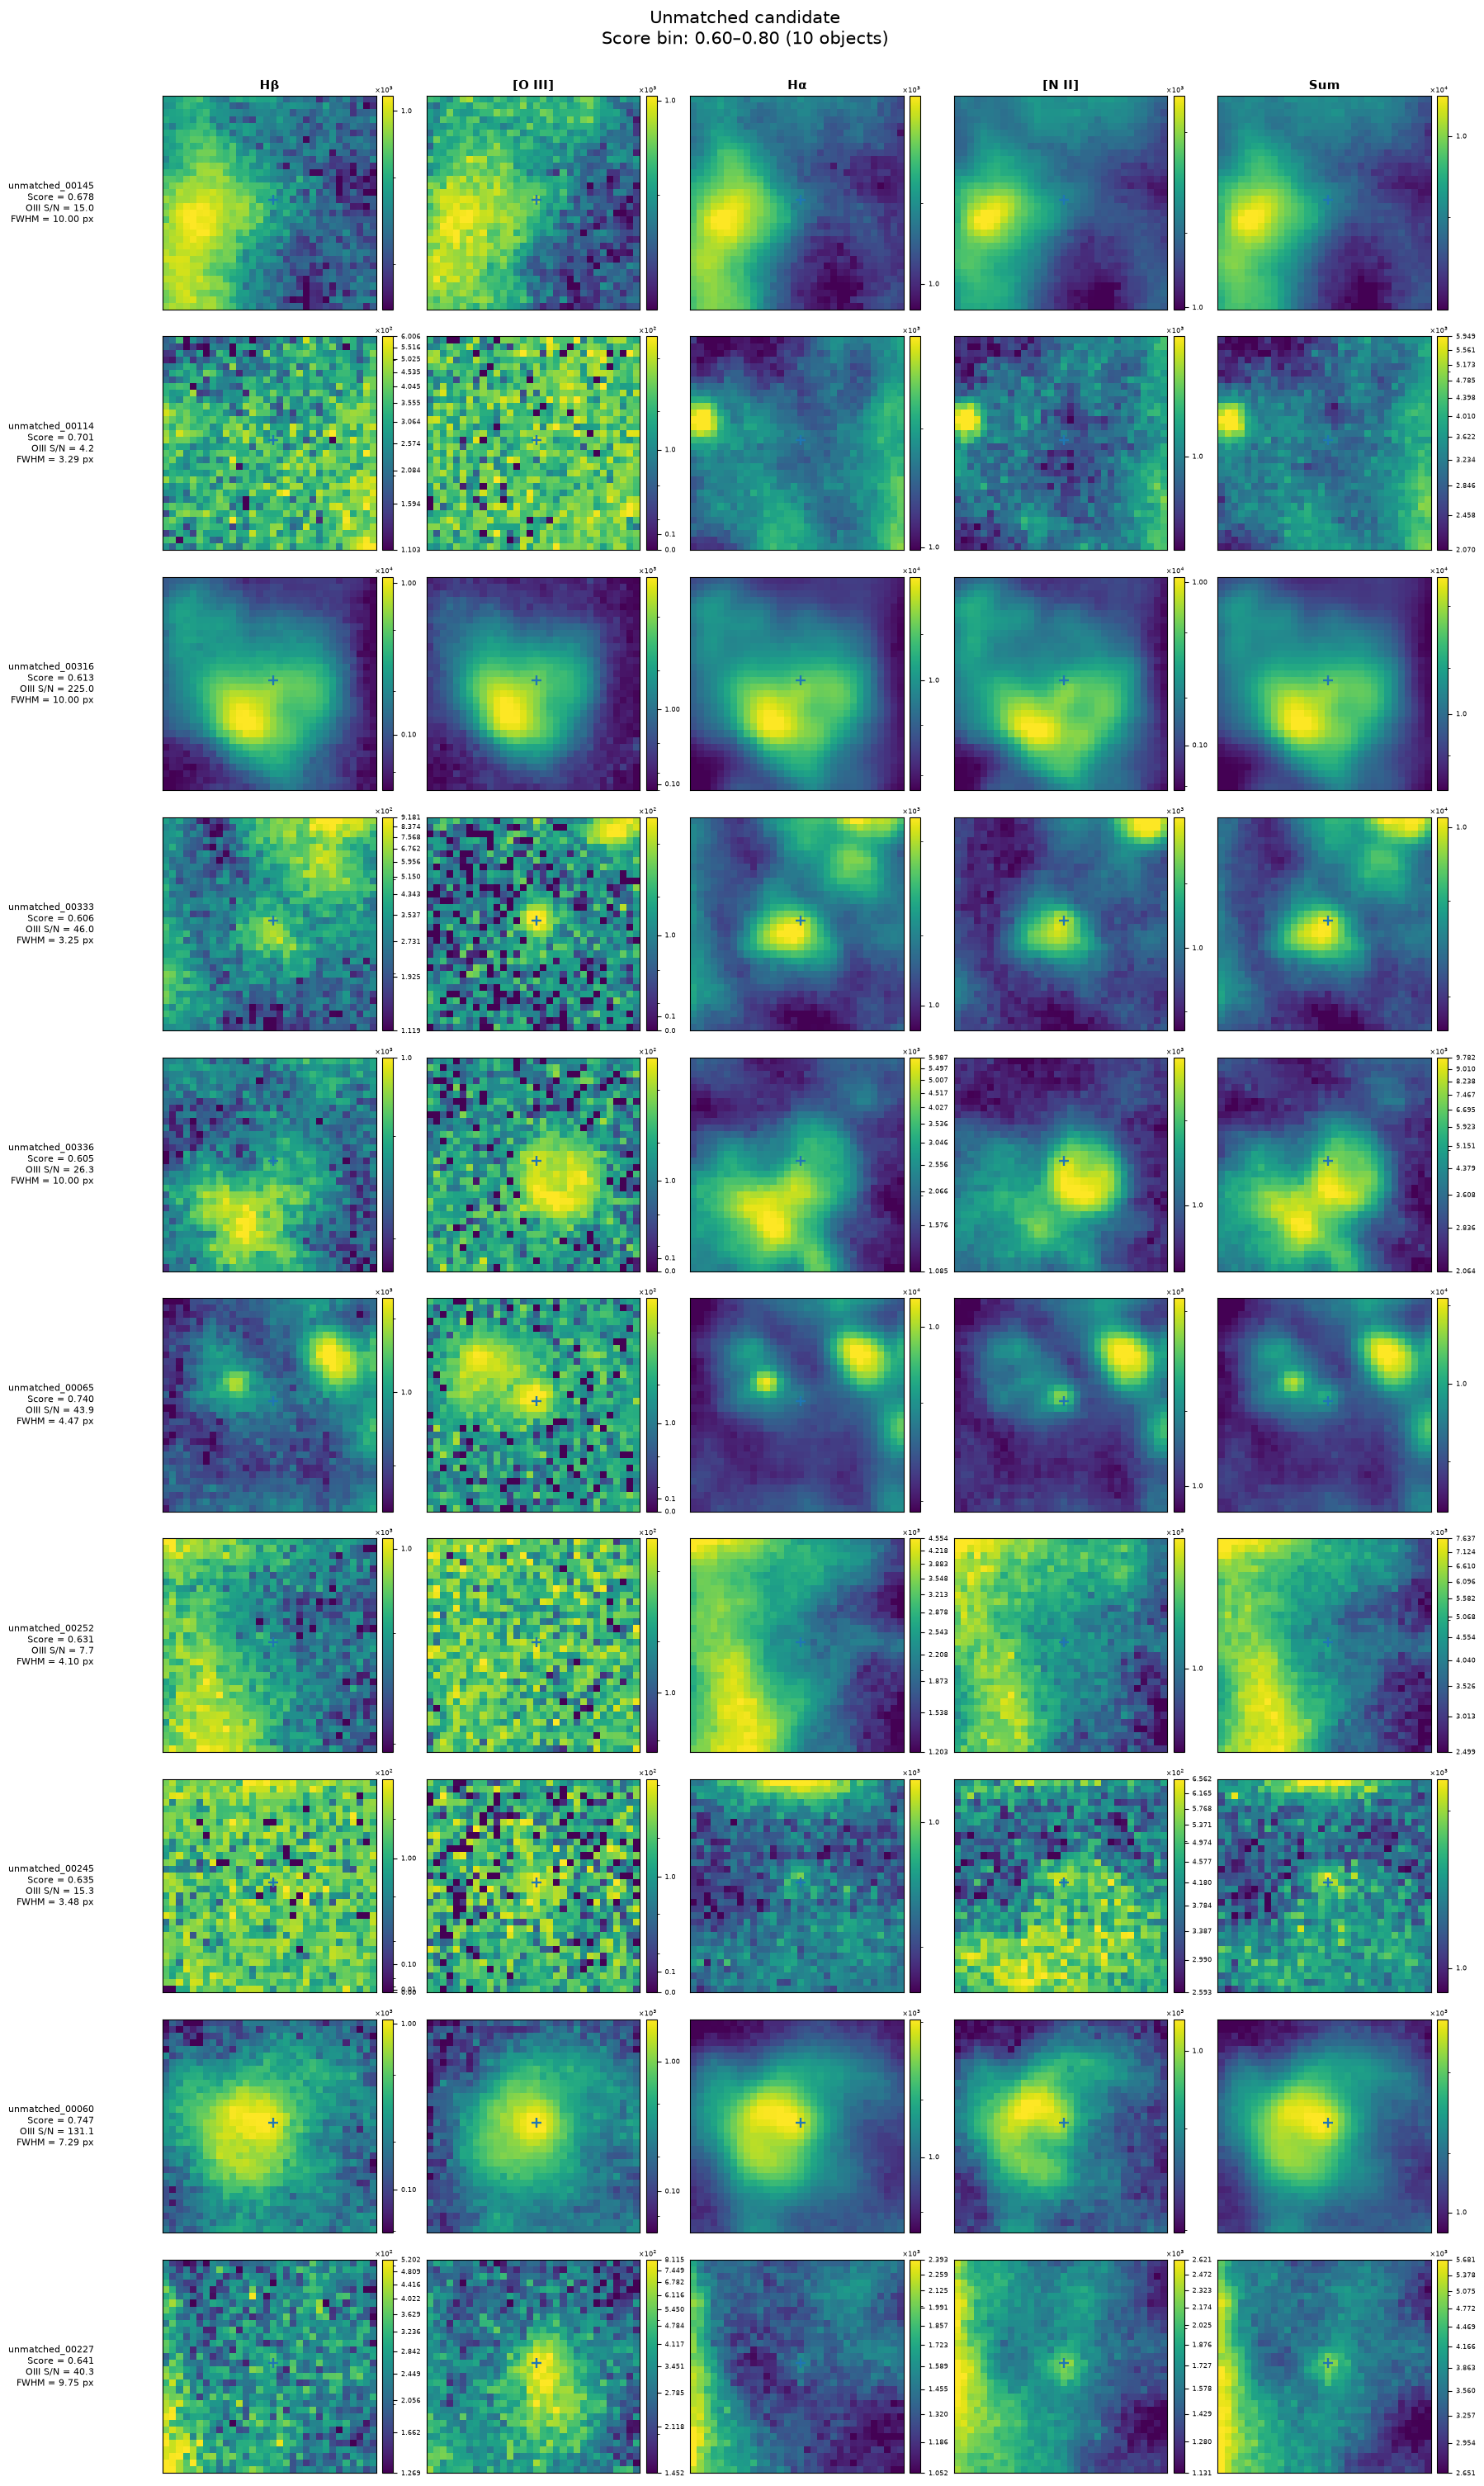

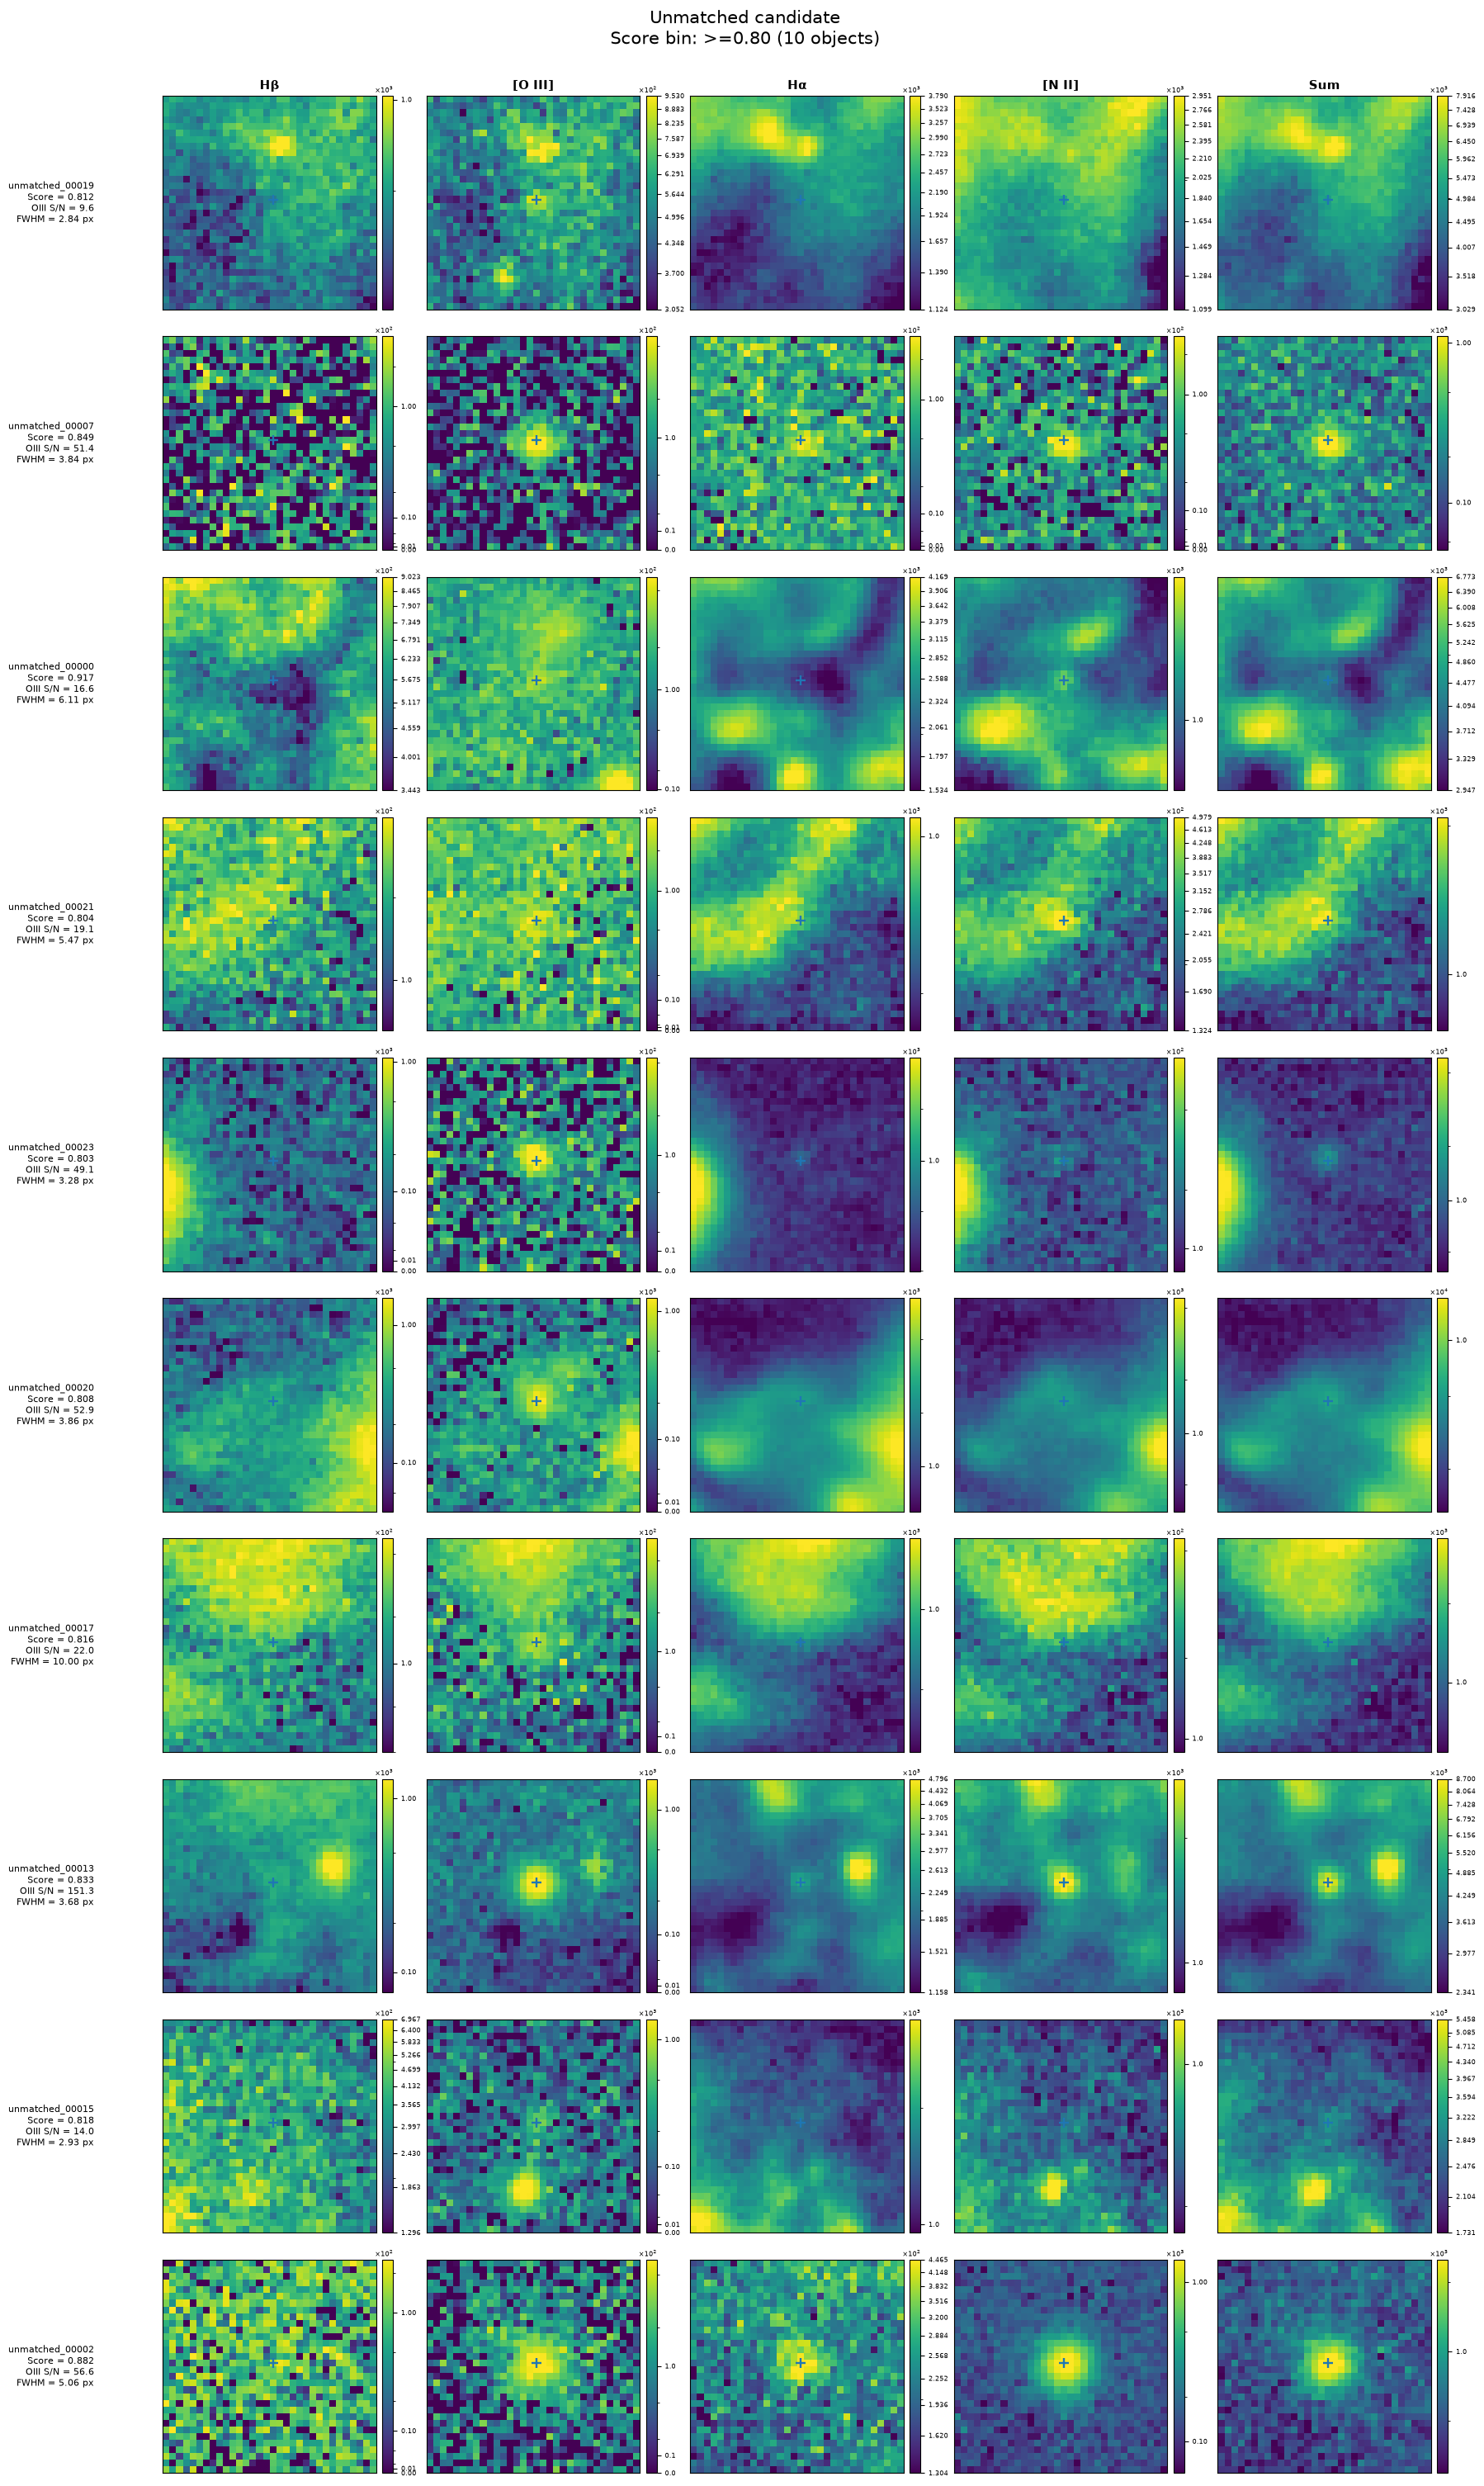

In [9]:
def add_position_markers(ax, source, population, origin):
    x0, y0 = origin
    if population in (POP_MATCHED, POP_UNMATCHED):
        ax.scatter(float(source["center_x"]) - x0, float(source["center_y"]) - y0, marker="+", s=85, linewidths=1.7)
    if population in (POP_MATCHED, POP_MISSED):
        ax.scatter(float(source["catalog_x"]) - x0, float(source["catalog_y"]) - y0, marker="x", s=70, linewidths=1.6)


def object_label(source, population):
    lines = [
        str(source["object_id"]),
        f"Score = {finite_value(source.get('network_score'), '.3f')}",
        f"OIII S/N = {finite_value(source.get('oiii_snr'), '.1f')}",
        f"FWHM = {finite_value(source.get('moffat_fwhm_pix'), '.2f')} px",
    ]
    if population == POP_MATCHED and np.isfinite(source.get("match_distance_pix", np.nan)):
        lines.append(f"Δr = {source['match_distance_pix']:.2f} px")
    return "\n".join(lines)


def add_flux_colorbar(fig, ax, image_artist):
    colorbar = fig.colorbar(image_artist, ax=ax, fraction=0.046, pad=0.025)
    formatter = ScalarFormatter(useMathText=True)
    formatter.set_scientific(True)
    formatter.set_powerlimits((-2, 2))
    colorbar.formatter = formatter
    colorbar.update_ticks()
    colorbar.ax.tick_params(labelsize=6)
    colorbar.ax.yaxis.get_offset_text().set_fontsize(6)


def plot_score_bin(sample, population, score_bin, channel_images=channel_images):
    chosen = sample.loc[
        sample["population"].eq(population) & sample["score_bin"].eq(score_bin)
    ].reset_index(drop=True)
    if chosen.empty:
        return

    fig, axes = plt.subplots(
        len(chosen), len(channel_images), figsize=(18, 3.0 * len(chosen)), squeeze=False
    )

    for row_index, source in chosen.iterrows():
        x_center, y_center = display_center(source, population)
        label = object_label(source, population)

        for column_index, (channel_name, image) in enumerate(channel_images.items()):
            ax = axes[row_index, column_index]
            cutout, origin = extract_cutout(image, x_center, y_center)
            if cutout is None:
                ax.text(0.5, 0.5, "No cutout", ha="center", va="center")
                ax.axis("off")
                continue

            artist = ax.imshow(cutout, origin="lower", norm=make_asinh_norm(cutout))
            add_position_markers(ax, source, population, origin)

            if row_index == 0:
                ax.set_title(channel_name, fontsize=11, fontweight="bold")
            if column_index == 0:
                ax.set_ylabel(label, fontsize=8, rotation=0, ha="right", va="center", labelpad=60)
            ax.set_xticks([])
            ax.set_yticks([])
            add_flux_colorbar(fig, ax, artist)

    fig.suptitle(f"{population}\nScore bin: {score_bin} ({len(chosen)} objects)", fontsize=15, y=1.002)
    fig.tight_layout()
    safe_name = f"{population}_{score_bin}".replace("/", "-").replace(" ", "_")
    # fig.savefig(OUTPUT_DIR / f"{safe_name}.png", dpi=180, bbox_inches="tight")
    plt.show()


for population, bins, _ in sample_specs:
    for _, _, score_label in bins:
        plot_score_bin(samples_by_population[population], population, score_label)


## 8. Optional: localization error versus catalogue/source properties


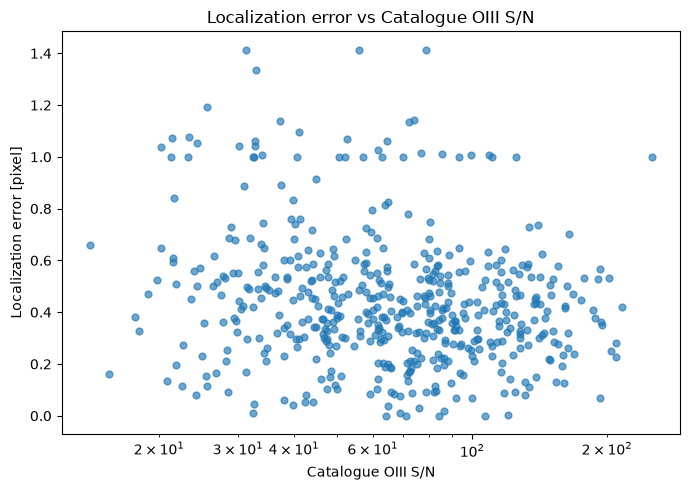

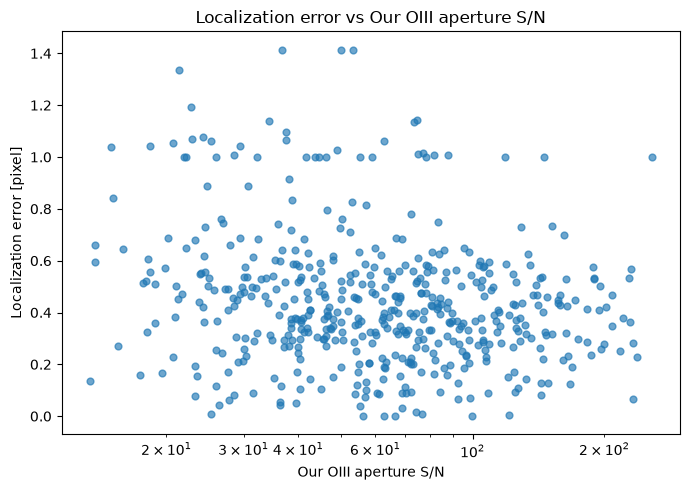

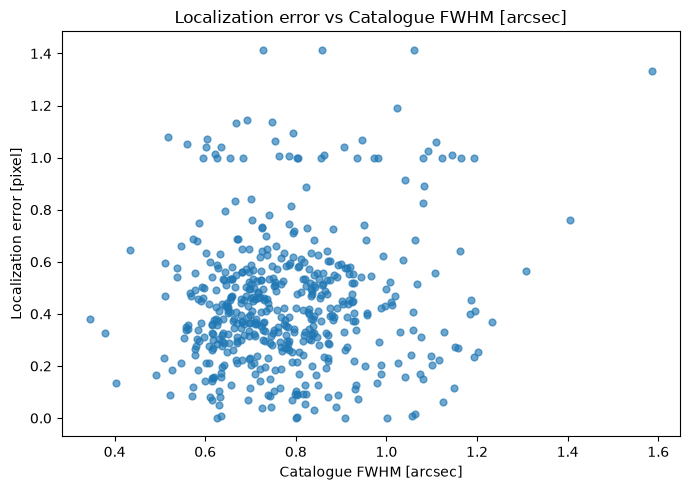

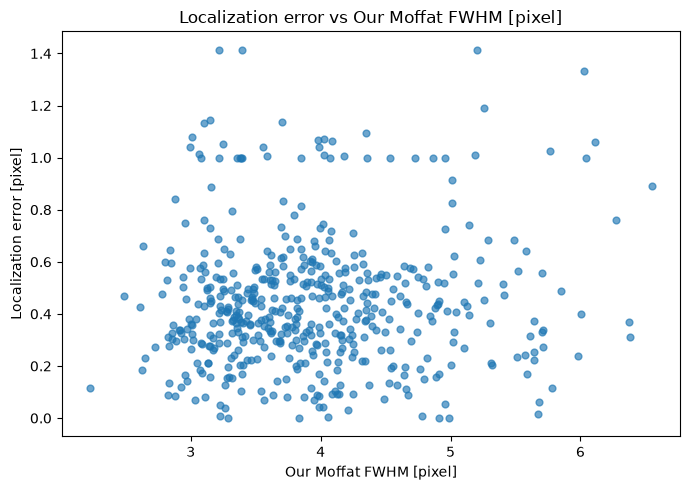

In [10]:
optional_properties = (
    ("catalog_oiii_snr", "Catalogue OIII S/N", True),
    ("oiii_snr", "Our OIII aperture S/N", True),
    ("catalog_fwhm_arcsec", "Catalogue FWHM [arcsec]", False),
    ("moffat_fwhm_pix", "Our Moffat FWHM [pixel]", False),
)

for column, xlabel, use_log_x in optional_properties:
    if column not in matched:
        continue

    valid = np.isfinite(matched[column]) & np.isfinite(matched["localization_error_pix"])
    if not valid.any():
        continue

    x = matched.loc[valid, column]
    y = matched.loc[valid, "localization_error_pix"]
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(x, y, s=24, alpha=0.65)
    if use_log_x and x.gt(0).all():
        ax.set_xscale("log")
    ax.set(xlabel=xlabel, ylabel="Localization error [pixel]", title=f"Localization error vs {xlabel}")
    fig.tight_layout()
    plt.show()


## Interpretation notes

- Radial localization error is defined only for recovered catalogue PNe.
- A non-zero mean $\Delta x$ or $\Delta y$ can indicate a systematic astrometric offset.
- The 68th, 90th, and 95th percentiles are more informative than the maximum for typical localization performance.
- Recovered cutouts help distinguish model offsets from blending or catalogue/astrometric uncertainty.
- Missed and unmatched samples are qualitative comparisons and do not have catalogue-defined localization errors.
